# Configurazione e Caricamento Dati

In [1]:
# Importazione delle Librerie
# Importi tutti i pacchetti necessari (pandas, numpy, matplotlib,
# sklearn per i modelli tradizionali e l'eventuale framework di Deep
# Learning per la regressione sequenziale).
import os
import glob
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,GroupKFold, StratifiedGroupKFold, GridSearchCV,learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, make_scorer, roc_auc_score, mean_absolute_error, r2_score, mean_squared_error
from sklearn.svm import SVC, SVR
from sklearn.calibration import CalibratedClassifierCV
from xgboost import XGBClassifier, XGBRegressor
from sklearn.neural_network import MLPClassifier
import matplotlib.pyplot as plt


RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [2]:
# Definizione delle Funzioni di Supporto (Igiene del Dato)
# Incolli le funzioni per elaborare i singoli file CSV.
# Qui implementi il downsampling (es. aggregare i dati ogni 10 o 30 secondi
# per togliere il rumore e alleggerire il calcolo) e calcoli la colonna
# fondamentale elapsed_min (i minuti passati dall'inizio del test).

def load_and_resample_battery_csv(file_path, resample_sec=10):
    """
    Reads a single telemetry CSV file, calculates elapsed time, and applies temporal
    downsampling based on a window of seconds (resample_sec).
    """
    # 1. Load the CSV file with the correct separator
    df = pd.read_csv(file_path, sep=';')
    
    # 2. Sequential sorting of the DataFrame based on the 'Tempo' column
    df['Tempo'] = pd.to_datetime(df['Tempo'], utc=True)
    df = df.sort_values('Tempo').reset_index(drop=True)
    
    # 3. Immediate calculation of the native time column (elapsed_min)
    # Indicates how many minutes have passed since the exact start of the test for this specific cell
    df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
    
    # 4. APPLYING DOWNSAMPLING (If requested)
    if resample_sec is not None and resample_sec > 1:
        # Set the timestamp as the temporal index to use Pandas' resample functions
        df = df.set_index('Tempo')
        
        # Aggregate by taking the mean of the physical values in the chosen second window
        # (e.g., if resample_sec=10, 10 rows per second become 1 row which is the mean of the 10)
        df_resampled = df.resample(f'{resample_sec}s').mean()
        
        # Restore the index and correctly recalculate the elapsed time column
        df = df_resampled.reset_index()
        df['elapsed_min'] = (df['Tempo'] - df['Tempo'].iloc[0]).dt.total_seconds() / 60.0
        
    return df

In [3]:
# Caricamento in Memoria dei File CSV Grezzi
# Cicli su tutti i file della cartella, applichi
# la funzione della Cella 2 e salvi i dataframe risultanti
# in un dizionario Python (es. dati_completi = {'nome_file.csv': df}).
# Nota: In questa fase non stai ancora tagliando il tempo, carichi le curve intere.

RAW_CSV_FOLDER = "data\\raw_csvs"

csv_files = sorted(glob.glob(os.path.join(RAW_CSV_FOLDER, "*.csv")))

battery_dict = {}

for file_path in csv_files:
    file_name = os.path.basename(file_path)
    df_clean = load_and_resample_battery_csv(file_path, resample_sec=10)
    if df_clean is not None and len(df_clean) > 0:
        battery_dict[file_name] = df_clean


In [4]:
list_unique_files = list(battery_dict.keys())

file_train_val, file_holdout_test = train_test_split(
    list_unique_files, 
    test_size=0.20, 
    random_state=RANDOM_SEED,
    shuffle=True
)

overlap = set(file_train_val).intersection(set(file_holdout_test))
assert len(overlap) == 0, "ERRORE: Rilevato mescolamento tra i file di Train e di Test!"
print("✓ Sicurezza Anti-Leakage confermata: nessuna sovrapposizione tra i due set.")

✓ Sicurezza Anti-Leakage confermata: nessuna sovrapposizione tra i due set.


# Task 1 - Classificazione Binaria Precoce (PASS/FAIL)

In [5]:
# Estrazione del Target Binario (La Verità)
# Per ogni file, guardi l'ultimo valore registrato di Capacity (Ah).
# Definisci la regola: se $C_{\text{finale}}
# \ge 5\text{ Ah} \implies \text{label} = 1$ (SUCCESS),
# altrimenti $0$ (FAIL). Assegni questa etichetta univoca a ogni file.

summary_train_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])
summary_test_df = pd.DataFrame(columns=['file_name', 'final_capacity', 'label'])

rows_train = []
rows_test = []

for file_name in file_train_val:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_train.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

for file_name in file_holdout_test:
    df = battery_dict[file_name]
    final_capacity = df['Capacity (Ah)'].iloc[-1]
    label = 1 if final_capacity >= 5.0 else 0
    rows_test.append({
        'file_name': file_name,
        'final_capacity': final_capacity,
        'label': label
    })

summary_train_df = pd.DataFrame(rows_train)
summary_test_df = pd.DataFrame(rows_test)

In [6]:
# Funzione di Troncamento e Creazione Feature (Una riga per Batteria)
# Definisci una funzione che prende una cella, taglia i dati al minuto
# $W$ (es. $W=60$ o $W=120$) e calcola le feature riassuntive di quella
# finestra (Tensione finale, pendenza/derivata della curva in quell'ora,
# media mobile, capacità accumulata fino a quel momento).
# Restituisce una sola riga per quel file.

def extract_features_from_battery(df, window_minutes=60, starting_minute = 0):
    """
    Extracts features from a battery DataFrame truncated to a specific time window.
    
    Parameters:
    - df: DataFrame containing the battery telemetry data.
    - window_minutes: The time window in minutes to truncate the data.
    - starting_minute: The starting minute from which to begin truncation.
    
    Returns:
    - A dictionary of extracted features.
    """
    # Truncate the DataFrame to the specified time window
    truncated_df = df[(df['elapsed_min'] >= starting_minute) & (df['elapsed_min'] <= starting_minute + window_minutes)]
    
    # Calculate features
    delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0] if len(truncated_df) > 1 else np.nan
    dv_dt = delta_voltage / window_minutes if not np.isnan(delta_voltage) else np.nan
    d2v_dt2 = (truncated_df['Tensione (V)'].iloc[-1] - 2 * truncated_df['Tensione (V)'].iloc[len(truncated_df)//2] + truncated_df['Tensione (V)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_mean = truncated_df['Tensione (V)'].mean() if not truncated_df.empty else np.nan
    v_std = truncated_df['Tensione (V)'].std() if not truncated_df.empty else np.nan
    delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1] if len(truncated_df) > 1 else np.nan
    dC_dt = delta_C / window_minutes if not np.isnan(delta_C) else np.nan
    d2C_dt2 = (truncated_df['Capacity (Ah)'].iloc[-1] - 2 * truncated_df['Capacity (Ah)'].iloc[len(truncated_df)//2] + truncated_df['Capacity (Ah)'].iloc[0]) / (window_minutes**2) if len(truncated_df) > 2 else np.nan
    v_start = truncated_df['Tensione (V)'].iloc[0] if not truncated_df.empty else np.nan
    v_end = truncated_df['Tensione (V)'].iloc[-1] if not truncated_df.empty else np.nan
    c_start = truncated_df['Capacity (Ah)'].iloc[0] if not truncated_df.empty else np.nan
    c_end = truncated_df['Capacity (Ah)'].iloc[-1] if not truncated_df.empty else np.nan
    
    return {
        'start_time': starting_minute,
        'end_time': starting_minute + window_minutes,
        'delta_voltage': delta_voltage,
        'dv_dt': dv_dt,
        'd2v_dt2': d2v_dt2,
        'mean_voltage': v_mean,
        'std_voltage': v_std,
        'delta_capacity': delta_C,
        'dC_dt': dC_dt,
        'd2C_dt2': d2C_dt2,
        'voltage_start': v_start,
        'voltage_end': v_end,
        'capacity_start': c_start,
        'capacity_end': c_end
    }

In [7]:
# Configurazione dello Schema di Validazione (GroupKFold)
# Incolli la tua funzione di validazione
# Configura un GroupKFold a 5 fold basato sull'ID del file.
# All'interno del ciclo dei fold inserisci una Pipeline con lo StandardScaler()
# e il modello (es. RandomForestClassifier o LogisticRegression(max_iter=300)).

#WINDOW_TARGET = [30,60,90,120,150,180,210,240,270,300]
FINESTRE_START_TEST = [0,30,60,90,120,150,180,210,240,270]
FINESTRE_TEST = [30,60,90,120,150,180,210,240,270,300]
features_train_list = []
features_test_list = []

for file_name in file_train_val:
    df_train = battery_dict[file_name]
    for i in range(len(FINESTRE_START_TEST)):
        features_train = extract_features_from_battery(df_train, window_minutes=FINESTRE_TEST[i], starting_minute=FINESTRE_START_TEST[i])
        features_train['file_name'] = file_name
        features_train['window'] = FINESTRE_TEST[i]
        features_train_list.append(features_train)

for file_name in file_holdout_test:
    df_test = battery_dict[file_name]
    for i in range(len(FINESTRE_START_TEST)):
        features_test = extract_features_from_battery(df_test, window_minutes=FINESTRE_TEST[i], starting_minute=FINESTRE_START_TEST[i])
        features_test['file_name'] = file_name
        features_test['window'] = FINESTRE_TEST[i]
        features_test_list.append(features_test)

df_classification_train = pd.DataFrame(features_train_list)
df_classification_test = pd.DataFrame(features_test_list)
print(f"✓ Matrice di addestramento creata!")
print(f"  - Dimensioni totali: {df_classification_train.shape[0]} righe, {df_classification_train.shape[1]} colonne.")
print(f"  - Numero di righe medio per batteria: {df_classification_train.shape[0] / len(file_train_val):.1f}")

✓ Matrice di addestramento creata!
  - Dimensioni totali: 520 righe, 16 colonne.
  - Numero di righe medio per batteria: 10.0


In [8]:
# Ciclo Sperimentale "ROC-AUC over Time" (Il Training e Validazione)
# Fai girare un ciclo for sulle finestre temporali che vuoi testare
# (es. 15min, 30min, 60min, 120min). Per ogni finestra, crei la matrice
# delle feature usando la Cella 6 (solo sui file di Train) e chiami la
# validazione della Cella 7. Salvi i punteggi di ROC-AUC Out-of-Fold.

def evaluate_model_on_window(df_matrix, model, n_splits=3):
    """
    [METODO DI TRAIN & TEST IN CV]
    Esegue lo scaling, l'addestramento e il test out-of-fold dei modelli 
    sulla matrice generata con il tuo metodo di estrazione feature.
    """
    # Colonne di metadati o target da escludere tassativamente dal fit dei modelli
    exclude_cols = {'file_name', 'label', 'start_time', 'end_time'}
    feature_cols = [c for c in df_matrix.columns if c not in exclude_cols]
    
    X = df_matrix[feature_cols].values
    y = df_matrix['label'].values
    groups = df_matrix['file_name'].values
    
    if len(np.unique(groups)) < n_splits or len(np.unique(y)) < 2:
        return np.nan
        
    sgkf = StratifiedGroupKFold(n_splits=n_splits)
    pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model)])
    
    oof_preds = np.zeros(len(df_matrix))
    
    for train_idx, val_idx in sgkf.split(X, y, groups):
        # FASE DI TRAINING
        pipeline.fit(X[train_idx], y[train_idx])
        
        # FASE DI TEST (Validazione Interna Out-of-Fold)
        if hasattr(pipeline, 'predict_proba'):
            oof_preds[val_idx] = pipeline.predict_proba(X[val_idx])[:, 1]
        else:
            oof_preds[val_idx] = pipeline.decision_function(X[val_idx])
            
    return roc_auc_score(y, oof_preds)

In [9]:
# Generazione del Grafico di Classificazione Precoce
# Plotti le curve di ROC-AUC dei modelli rispetto ai minuti passati
# (Asse X = Minuti, Asse Y = ROC-AUC). Questo grafico dimostra visivamente
# dopo quanti minuti lo spazio delle feature diventa separabile.

# 1. Configurazione della griglia temporale di cut-off (da t=0 fino a W minuti)
# FINESTRE_START_TEST = [0,0,0,0,0,0,0,0,0,0]


modelli = {
        "Logistic Regression": LogisticRegression(
        solver='liblinear', class_weight='balanced',
        max_iter=1000, random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=8, class_weight='balanced',
        n_jobs=-1, random_state=RANDOM_SEED
    ),    
    "SVM": CalibratedClassifierCV(
        estimator=SVC(
            kernel='rbf',        # maps data to infinite-dimensional space (Gaussian kernel)
            C=1.0,               # regularization
            gamma='scale',       # 1 / (n_features * X.var()) — good default
            class_weight='balanced',
            random_state=RANDOM_SEED
        ),
        method='sigmoid',        # Platt scaling (standard for SVMs)
        cv=3,                    # 3-fold internal cross-validation for calibration
        ensemble=False           # trains a single final SVC on the full dataset
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        n_jobs=-1, eval_metric='logloss', random_state=RANDOM_SEED
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
        alpha=0.01, max_iter=300, early_stopping=True, random_state=RANDOM_SEED
    ),
    }

def evaluate_models(
        models, 
        window_start, 
        window_end,
        battery_dict, 
        summary_train_df, 
        file_train_val):
    
    storico_risultati = {name: [] for name in models.keys()}

    # 2. Ciclo principale di estrazione e validazione
    for i in range(len(window_start)):
        records_finestra = []
        w_end = window_end[i]
        w_start = window_start[i]
        
        for file_name in file_train_val:
            df_bat = battery_dict[file_name] # Usa il nome del tuo dizionario in memoria
            label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
            
            # Invocazione del TUO metodo nativo: partiamo da 0 e analizziamo un'ampiezza di 'w' minuti
            feat_dict = extract_features_from_battery(df_bat, window_minutes=w_end, starting_minute=w_start)
            
            # Se la serie contiene dati validi e non NaNs bloccanti
            if feat_dict is not None and not np.isnan(feat_dict['delta_voltage']):
                feat_dict['label'] = label
                feat_dict['file_name'] = file_name
                records_finestra.append(feat_dict)
                
        if not records_finestra:
            for name in models.keys(): storico_risultati[name].append(np.nan)
            continue
            
        # Convertiamo la lista di dizionari generata dal tuo metodo in un DataFrame pulito
        df_matrice_w = pd.DataFrame(records_finestra)
        
        # Riempiamo eventuali buchi di calcolo per le derivate seconde (bfill/ffill di sicurezza d'esame)
        df_matrice_w = df_matrice_w.bfill().ffill()
        
        # Valutazione
        for name, model in models.items():
            auc_score = evaluate_model_on_window(df_matrice_w, model)
            storico_risultati[name].append(auc_score)
            #print(f"Cut-off {w_start:3d}-{w_end:3d} min | Modello: {name:20s} | CV ROC-AUC: {auc_score:.4f}")

    return storico_risultati

storico_risultati = evaluate_models(
    models=modelli,
    window_start=FINESTRE_START_TEST,
    window_end=FINESTRE_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val)
    

In [10]:
# Test Finale (Holdout) della Classificazione
# Scegli il modello migliore e la finestra ottimale (es. 60 minuti).
# Alleni il modello sull'intero set di Training (0-60 min).
# Prendi i file di Test messi da parte nella Cella 4, li tronchi a 60 minuti,
# estrai le feature e fai la predizione finale. Generi la Matrice di Confusione
# per l'esame.

def plot_roc_auc_over_time(storico_risultati, finestre_test):
    """
    Plots the ROC-AUC scores over time for different models.
    
    Parameters:
    - storico_risultati: Dictionary containing model names as keys and lists of ROC-AUC scores as values.
    - finestre_test: List of time windows corresponding to the ROC-AUC scores.
    """
    plt.figure(figsize=(10, 6))

    for name, scores in storico_risultati.items():
        plt.plot(finestre_test, scores, marker='o', lw=2, label=name)

    plt.axhline(0.90, color='r', linestyle='--', alpha=0.6, label='Soglia di Accettabilità Industriale (0.90)')
    plt.title("Evoluzione della Separabilità Precoce (Task Classificazione Binaria)")
    plt.xlabel("Tempo di Osservazione Parziale (Minuti dall'inizio della scarica)")
    plt.ylabel("Mean Out-of-Fold ROC-AUC")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

In [11]:

# Usiamo la finestra ottimale emersa dai tuoi test (es. 60 minuti)
START_WINDOW = 60
END_WINDOW = 90

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Costruzione della matrice di Train per il Tuning
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['file_name'] = file_name
        feat['label'] = label
        train_records.append(feat)
        
df_tuning = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_tuning.columns if c not in exclude_cols]

X_train = df_tuning[feature_names].values
y_train = df_tuning['label'].values
groups_train = df_tuning['file_name'].values

# 2. Definizione delle "Griglie" di parametri per ciascun modello
# NOTA: Usando la Pipeline, dobbiamo anteporre 'clf__' ai nomi dei parametri!
param_grids = {
    "Logistic Regression": {
        'clf__C': [0.01, 0.1, 1.0, 10.0],
        'clf__l1_ratio': [0.0, 1.0]
    },
    "Random Forest": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8, 12],
        'clf__min_samples_split': [2, 5]
    },
    "SVM": {
        # Per la SVM calibrata, dobbiamo entrare dentro l'estimator specficiando 'clf__estimator__'
        'clf__estimator__C': [0.1, 1.0, 10.0],
        'clf__estimator__kernel': ['linear', 'rbf'],
        'clf__estimator__gamma': ['scale', 'auto']
    },
    "XGBoost": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 6],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "MLP": {
        'clf__hidden_layer_sizes': [(32, 16), (64, 32), (64, 64)],
        'clf__alpha': [0.001, 0.01, 0.1]
    }
}

# Dizionario dove salveremo i modelli ottimizzati pronti per il test set finale
modelli_ottimizzati = {}

# 3. Ciclo di ottimizzazione
sgkf = StratifiedGroupKFold(n_splits=5)

for name, model_instance in modelli.items():   
    # Creiamo la pipeline standardizzata
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', model_instance)
    ])
    
    # Configuriaramo il GridSearch con StratifiedGroupKFold e scoring basato su ROC-AUC
    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=sgkf,
        scoring='roc_auc',
        n_jobs=-1,
        verbose=1
    )
    
    # Eseguiamo il fit passando esplicitamente i gruppi (i nomi dei file delle batterie)
    grid_search.fit(X_train, y_train, groups=groups_train)
    
    # Salviamo il modello migliore (già ri-addestrato su tutto X_train con i parametri ottimi)
    modelli_ottimizzati[name] = grid_search.best_estimator_

optimized_results = evaluate_models(
    models=modelli_ottimizzati,
    window_start=FINESTRE_START_TEST,
    window_end=FINESTRE_TEST,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 24 candidates, totalling 120 fits
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Fitting 5 folds for each of 27 candidates, totalling 135 fits


c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Fitting 5 folds for each of 9 candidates, totalling 45 fits


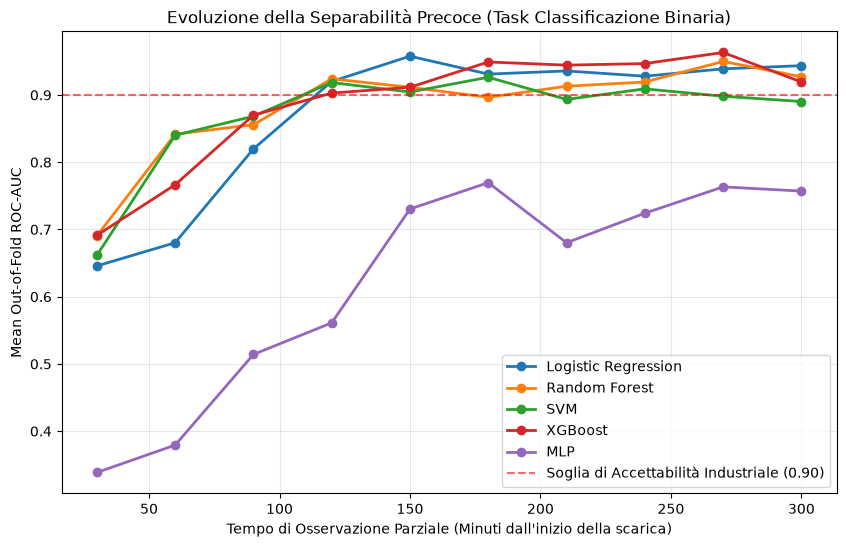

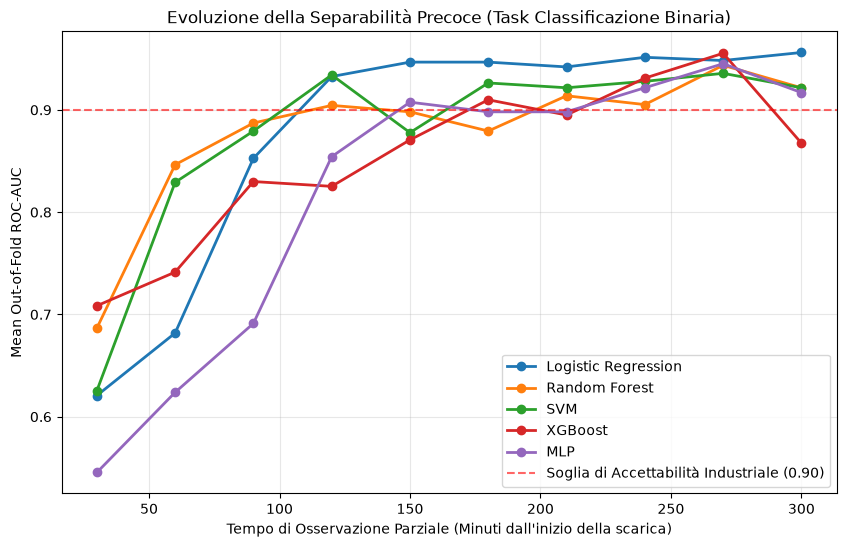

In [12]:
plot_roc_auc_over_time(storico_risultati, FINESTRE_TEST)
plot_roc_auc_over_time(optimized_results, FINESTRE_TEST)

              precision    recall  f1-score   support

        FAIL       1.00      0.62      0.77         8
     SUCCESS       0.62      1.00      0.77         5

    accuracy                           0.77        13
   macro avg       0.81      0.81      0.77        13
weighted avg       0.86      0.77      0.77        13



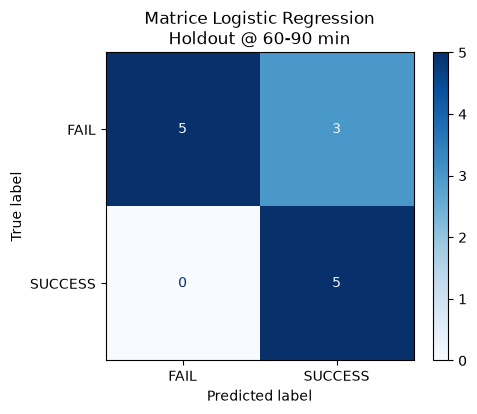

              precision    recall  f1-score   support

        FAIL       1.00      0.75      0.86         8
     SUCCESS       0.71      1.00      0.83         5

    accuracy                           0.85        13
   macro avg       0.86      0.88      0.85        13
weighted avg       0.89      0.85      0.85        13



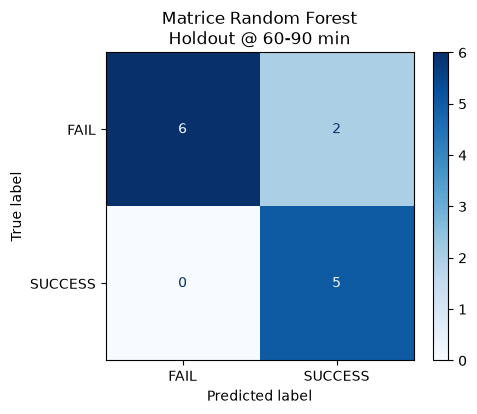

              precision    recall  f1-score   support

        FAIL       1.00      0.62      0.77         8
     SUCCESS       0.62      1.00      0.77         5

    accuracy                           0.77        13
   macro avg       0.81      0.81      0.77        13
weighted avg       0.86      0.77      0.77        13



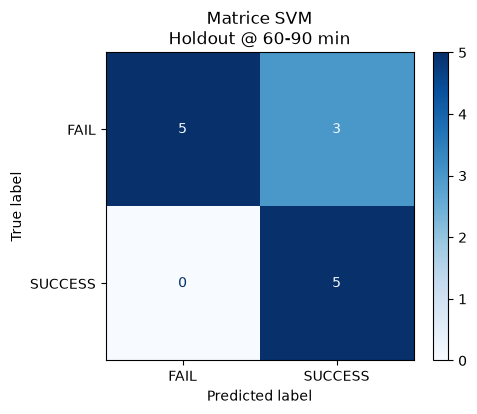

              precision    recall  f1-score   support

        FAIL       1.00      0.50      0.67         8
     SUCCESS       0.56      1.00      0.71         5

    accuracy                           0.69        13
   macro avg       0.78      0.75      0.69        13
weighted avg       0.83      0.69      0.68        13



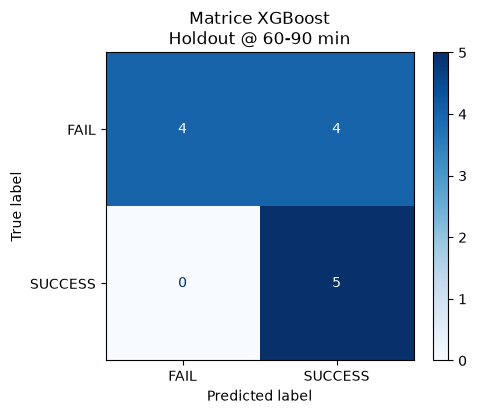

              precision    recall  f1-score   support

        FAIL       0.73      1.00      0.84         8
     SUCCESS       1.00      0.40      0.57         5

    accuracy                           0.77        13
   macro avg       0.86      0.70      0.71        13
weighted avg       0.83      0.77      0.74        13



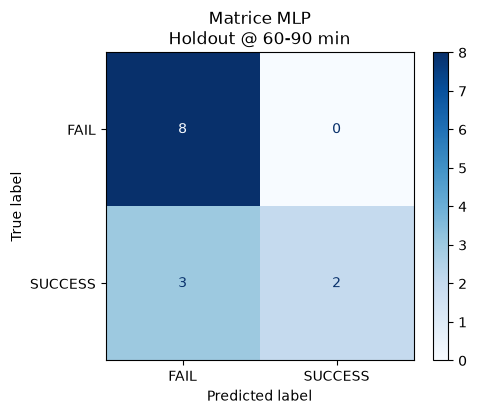

In [13]:
# ==========================================
# CELLA 10: TEST FINALE DINAMICO SU TUTTI I MODELLI (HOLDOUT SET)
# ==========================================

exclude_cols = {'label', 'file_name', 'start_time', 'end_time'}

# 1. Preparazione dell'intero Training Set alla finestra stabilita
train_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    label = summary_train_df[summary_train_df['file_name'] == file_name]['label'].values[0]
    
    # Invocazione del tuo metodo nativo
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        train_records.append(feat)
        
df_train_final = pd.DataFrame(train_records).bfill().ffill()
feature_names = [c for c in df_train_final.columns if c not in exclude_cols]

X_train_f = df_train_final[feature_names].values
y_train_f = df_train_final['label'].values


# 2. Preparazione dell'Holdout Test Set (Dati mai visti, sigillati all'inizio)
test_records = []
for file_name in file_holdout_test:
    df_bat = battery_dict[file_name]
    label = summary_test_df[summary_test_df['file_name'] == file_name]['label'].values[0]
    
    feat = extract_features_from_battery(df_bat, window_minutes=END_WINDOW, starting_minute=START_WINDOW)
    if feat is not None and not np.isnan(feat['delta_voltage']):
        feat['label'] = label
        test_records.append(feat)
        
df_test_final = pd.DataFrame(test_records).bfill().ffill()

X_test_f = df_test_final[feature_names].values
y_test_f = df_test_final['label'].values


# 3. Ciclo dinamico di Fit e Test su ogni modello configurato
for name, model_instance in modelli_ottimizzati.items():
    
    # Creiamo una pipeline fresca per il modello corrente per garantire lo scaling isolato
    pipeline_definitiva = Pipeline([
        ('scaler', StandardScaler()), 
        ('clf', model_instance)
    ])
    
    # --- FIT GLOBAL SUL TRAIN SET ---
    pipeline_definitiva.fit(X_train_f, y_train_f)
    
    # --- PREDDIZIONE SULL'HOLDOUT SET ---
    y_pred_f = pipeline_definitiva.predict(X_test_f)
    
    # Stampa dei risultati testuali (Precision, Recall, F1-Score)
    print(classification_report(y_test_f, y_pred_f, target_names=['FAIL', 'SUCCESS']))
    
    # Generazione e visualizzazione della Matrice di Confusione
    cm = confusion_matrix(y_test_f, y_pred_f)
    fig, ax = plt.subplots(figsize=(5, 4))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['FAIL', 'SUCCESS'])
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
    plt.title(f"Matrice {name}\nHoldout @ {START_WINDOW}-{END_WINDOW} min")
    plt.show()

In [14]:
def plot_learning_curve(
        models_to_analyze,
        X_train,
        y_train,
        groups_train):
    
    for model_name, model_to_analyze in models_to_analyze.items():
        sgkf = StratifiedGroupKFold(n_splits=3)
        train_sizes, train_scores, test_scores = learning_curve(
            estimator=model_to_analyze,
            X=X_train,
            y=y_train,
            groups=groups_train,
            train_sizes=np.linspace(0.2, 1.0, 5),
            cv=sgkf,
            scoring='roc_auc',
            n_jobs=-1,
            random_state=RANDOM_SEED
        )
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        test_mean = np.mean(test_scores, axis=1)
        test_std = np.std(test_scores, axis=1)

        plt.figure(figsize=(10, 6))
        plt.plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training ROC-AUC')
        plt.fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')

        plt.plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation ROC-AUC (CV)')
        plt.fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

        plt.title("Learning Curves - Modello: {}".format(model_name))
        plt.xlabel("Numero di campioni (Batterie) usati nel Training")
        plt.ylabel("Punteggio ROC-AUC")
        plt.grid(True, alpha=0.3)
        plt.legend(loc='lower right')
        plt.show()

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

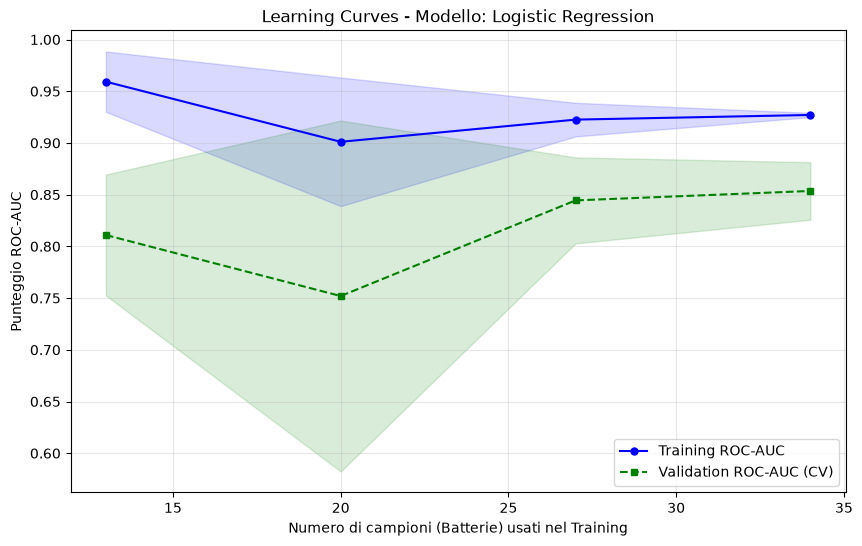

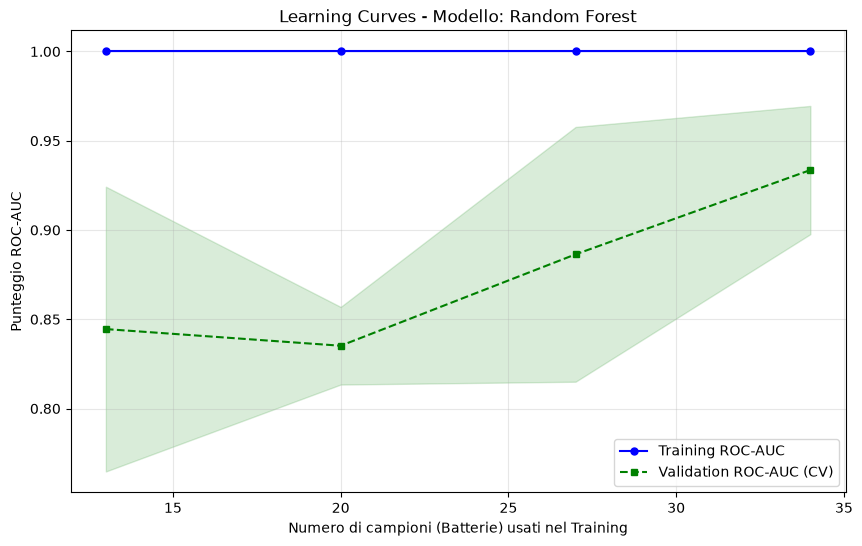

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
4 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

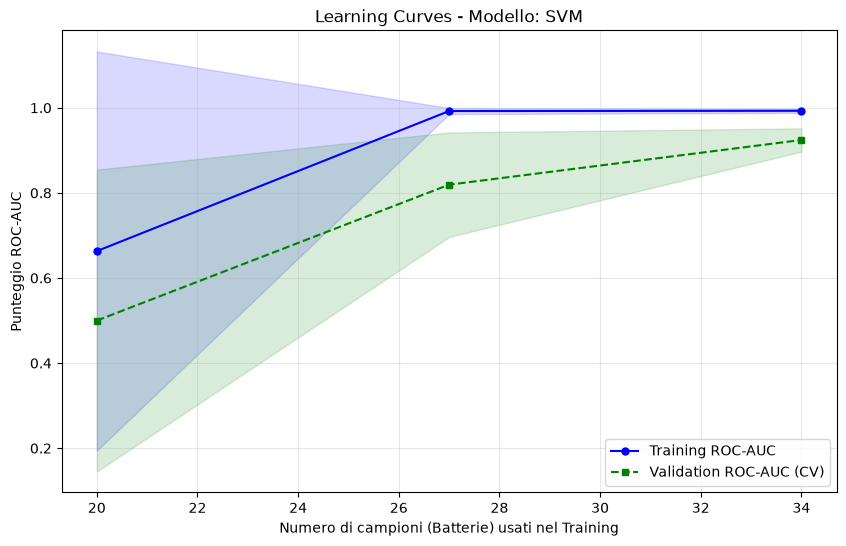

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

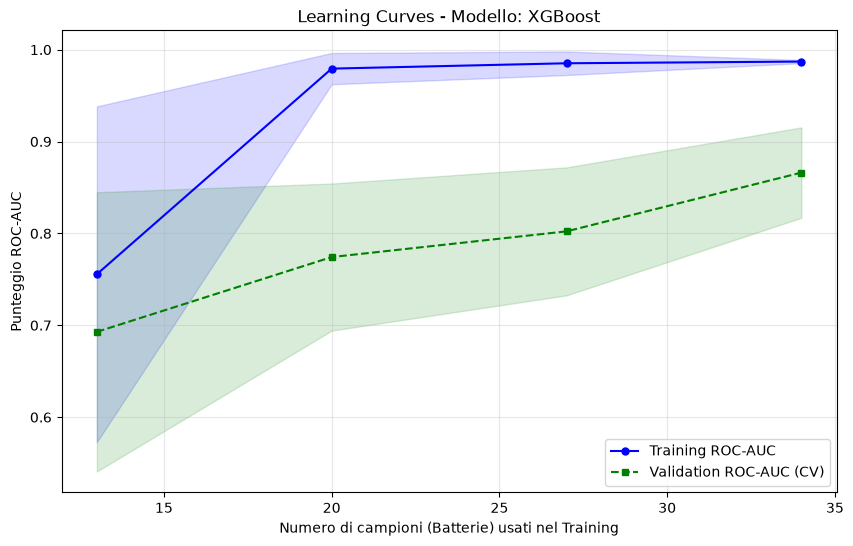

c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
3 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\model_selection\_validation.py", line 856, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\sfori\anaconda3\envs\battery-ml\Lib\site-packages\sklear

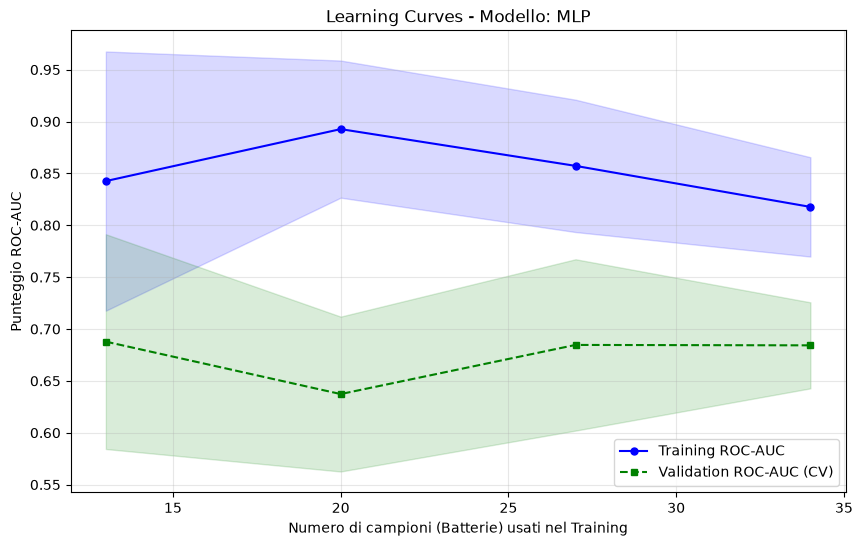

In [15]:
plot_learning_curve(
    models_to_analyze=modelli_ottimizzati,
    X_train=X_train_f,
    y_train=y_train_f,
    groups_train=groups_train
)

# Task 2 - Regressione Precoce (Stima della Capacità Esatta)

## Regression with Machine Learning Models

In [16]:
# aggregation by step of 10 minutes

# Configurazione della finestra critica e dei blocchi storici a ritroso
MINUTO_FINE_OSSERVAZIONE = 500
AMPIEZZA_BLOCCO_MINUTI = 20
NUMERO_LAG = 4  # Genera i blocchi temporali: t (80-90), t-1 (70-80), t-2 (60-70), t-3 (60-70)

# Sostituisci con il nome reale della colonna della capacità finale nel tuo summary_df
COLONNA_TARGET_Y = 'final_capacity' 

def extract_regression_lagged_features(df, base_window_min=10, steps=3, end_minute=90):
    """
    Estrae le feature fisiche aggregando i dati in blocchi temporali a ritroso.
    Restituisce un unico dizionario piatto con le feature laggate (_t, _t-1, _t-2, _t-3).
    """
    all_features = {}
    
    for step in range(steps):
        # Calcolo dei confini temporali del blocco corrente
        w_start = end_minute - (step + 1) * base_window_min
        w_end = end_minute - step * base_window_min
        
        if w_start < 0:
            break
            
        # Filtriamo il subset temporale del CSV della singola batteria
        truncated_df = df[(df['elapsed_min'] >= w_start) & (df['elapsed_min'] <= w_end)]
        
        # Controllo di sicurezza se mancano record nel blocco
        if len(truncated_df) < 2:
            return None 
            
        # Calcolo delle pendenze fisiche e medie sul blocco
        delta_voltage = truncated_df['Tensione (V)'].iloc[-1] - truncated_df['Tensione (V)'].iloc[0]
        dv_dt = delta_voltage / base_window_min
        v_mean = truncated_df['Tensione (V)'].mean()
        v_std = truncated_df['Tensione (V)'].std()
        
        delta_C = truncated_df['Capacity (Ah)'].iloc[0] - truncated_df['Capacity (Ah)'].iloc[-1]
        dC_dt = delta_C / base_window_min
        
        v_start = truncated_df['Tensione (V)'].iloc[0]
        v_end = truncated_df['Tensione (V)'].iloc[-1]
        c_end = truncated_df['Capacity (Ah)'].iloc[-1]
        
        # Suffisso identificativo del ritardo temporale
        suffix = f"_t" if step == 0 else f"_t-{step}"
        
        # Mappatura delle feature
        all_features[f'dv_dt{suffix}'] = dv_dt
        all_features[f'mean_voltage{suffix}'] = v_mean
        all_features[f'std_voltage{suffix}'] = v_std
        all_features[f'dC_dt{suffix}'] = dC_dt
        all_features[f'voltage_start{suffix}'] = v_start
        all_features[f'voltage_end{suffix}'] = v_end
        all_features[f'capacity_end{suffix}'] = c_end

    return all_features

# --- 1. ESTRAZIONE TRAIN / VALIDATION DATASET ---
train_regression_records = []
for file_name in file_train_val:
    df_bat = battery_dict[file_name]
    # Recuperiamo il valore continuo della capacità reale dal summary
    y_val = summary_train_df[summary_train_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val  # Nuovo target Continuo (Y)
        train_regression_records.append(feat_reg)

df_reg_train = pd.DataFrame(train_regression_records).bfill().ffill()

# --- 2. ESTRAZIONE HOLDOUT TEST DATASET ---
test_regression_records = []
for file_name in file_holdout_test:
    df_bat = battery_dict[file_name]
    y_val = summary_test_df[summary_test_df['file_name'] == file_name][COLONNA_TARGET_Y].values[0]
    
    feat_reg = extract_regression_lagged_features(
        df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=MINUTO_FINE_OSSERVAZIONE
    )
    
    if feat_reg is not None:
        feat_reg['file_name'] = file_name
        feat_reg['target_capacity'] = y_val
        test_regression_records.append(feat_reg)

df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()

# --- 3. ISOLAMENTO DELLE MATRICI NDARRAY PER SCIKIT-LEAR ---
exclude_reg_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
feature_reg_names = [c for c in df_reg_train.columns if c not in exclude_reg_cols]

X_train_r = df_reg_train[feature_reg_names].values
y_train_r = df_reg_train['target_capacity'].values
groups_train_r = df_reg_train['file_name'].values

X_test_r = df_reg_test[feature_reg_names].values
y_test_r = df_reg_test['target_capacity'].values

print(f"✓ Dataset Regressione pronto!")
print(f"-> Matrice Train: {X_train_r.shape[0]} batterie, {X_train_r.shape[1]} feature laggate.")
print(f"-> Matrice Test:  {X_test_r.shape[0]} batterie.")

✓ Dataset Regressione pronto!
-> Matrice Train: 52 batterie, 28 feature laggate.
-> Matrice Test:  12 batterie.


In [17]:
modelli_regressione = {
    "Random Forest Regressor": RandomForestRegressor(random_state=RANDOM_SEED, n_jobs=-1),
    "XGBoost Regressor": XGBRegressor(random_state=RANDOM_SEED, n_jobs=-1, eval_metric='rmse'),
    "Support Vector Regressor (SVR)": SVR()
}

# Griglie di iperparametri specifiche per compiti di regressione
param_grids_regression = {
    "Random Forest Regressor": {
        'clf__n_estimators': [50, 100, 200],
        'clf__max_depth': [4, 6, 8],
        'clf__min_samples_leaf': [1, 3, 5]
    },
    "XGBoost Regressor": {
        'clf__n_estimators': [50, 100, 150],
        'clf__max_depth': [3, 4, 5],
        'clf__learning_rate': [0.01, 0.05, 0.1]
    },
    "Support Vector Regressor (SVR)": {
        'clf__C': [0.1, 1.0, 10.0, 50.0],
        'clf__kernel': ['linear', 'rbf'],
        'clf__gamma': ['scale', 'auto']
    }
}

In [18]:
'''def tune_regression_models_on_window(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    """
    Estrae le feature fino al cut_off_minute richiesto ed effettua il tuning
    iperparametrico basato su GroupKFold (ottimizzando l'MSE).
    """
    print(f"\n" + "="*70)
    # Calcolo dinamico: se inserisci 120, estrae la storia a ritroso da lì
    print(f" AVVIO TUNING REGRESSIONE - DATI DISPONIBILI FINO AL MINUTO: {cut_off_minute}")
    print("="*70)
    
    # 1. Estrazione dinamica delle feature storiche basate sul cut-off
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        # Recuperiamo il valore reale continuo della capacità
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Estrattore a blocchi di 10 minuti (definito nel passaggio precedente)
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=10, steps=3, end_minute=cut_off_minute
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    if not records_tuning:
        print(f"❌ Errore: Nessun dato estratto per il minuto {cut_off_minute}. Controlla la lunghezza dei CSV.")
        return None
        
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    # 2. Ciclo di ottimizzazione sui 3 modelli scelti
    modelli_reg_ottimizzati = {}
    gkf = GroupKFold(n_splits=5)
    
    for name, model_instance in modelli_regressione.items():
        print(f"\nTuning in corso per {name}...")
        
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('clf', model_instance)
        ])
        
        # GridSearch tarato sul Mean Squared Error
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error', # Ottimizziamo l'errore quadratico
            n_jobs=-1,
            verbose=0
        )
        
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Convertiamo il punteggio negativo in RMSE reale (radice dell'errore quadratico) per facilità di lettura
        best_rmse = np.sqrt(-grid_search.best_score_)
        
        print(f" -> Migliori Parametri: {grid_search.best_params_}")
        print(f" -> Miglior RMSE medio in CV: {best_rmse:.4f} Ah")
        
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        
    return modelli_reg_ottimizzati, feature_names'''

'def tune_regression_models_on_window(cut_off_minute, battery_dict, summary_train_df, file_train_val):\n    """\n    Estrae le feature fino al cut_off_minute richiesto ed effettua il tuning\n    iperparametrico basato su GroupKFold (ottimizzando l\'MSE).\n    """\n    print(f"\n" + "="*70)\n    # Calcolo dinamico: se inserisci 120, estrae la storia a ritroso da lì\n    print(f" AVVIO TUNING REGRESSIONE - DATI DISPONIBILI FINO AL MINUTO: {cut_off_minute}")\n    print("="*70)\n    \n    # 1. Estrazione dinamica delle feature storiche basate sul cut-off\n    records_tuning = []\n    for file_name in file_train_val:\n        df_bat = battery_dict[file_name]\n        # Recuperiamo il valore reale continuo della capacità\n        y_val = summary_train_df[summary_train_df[\'file_name\'] == file_name][\'final_capacity\'].values[0]\n        \n        # Estrattore a blocchi di 10 minuti (definito nel passaggio precedente)\n        feat_reg = extract_regression_lagged_features(\n            df_ba

In [19]:
# Lancio del tuning impostando la finestra temporale desiderata (es. 150 minuti)
'''MINUTI_OSSERVAZIONE = 150

modelli_reg_ottimi, feature_reg_selezionate = tune_regression_models_on_window(
    cut_off_minute=MINUTI_OSSERVAZIONE,
    battery_dict=battery_dict,
    summary_train_df=summary_train_df,
    file_train_val=file_train_val
)'''

'MINUTI_OSSERVAZIONE = 150\n\nmodelli_reg_ottimi, feature_reg_selezionate = tune_regression_models_on_window(\n    cut_off_minute=MINUTI_OSSERVAZIONE,\n    battery_dict=battery_dict,\n    summary_train_df=summary_train_df,\n    file_train_val=file_train_val\n)'

In [20]:
# Liste per salvare i punteggi da plottare
nomi_modelli = []
rmse_train_list = []
rmse_val_list = []

# NOTA OTTIMIZZATA: Per integrarlo direttamente nel tuo flusso attuale, ecco la funzione di tuning 
# modificata che sputa fuori il grafico di Overfitting/Underfitting automaticamente:

def tune_and_diagnose_regression(cut_off_minute, battery_dict, summary_train_df, file_train_val):
    records_tuning = []
    for file_name in file_train_val:
        df_bat = battery_dict[file_name]
        y_val = summary_train_df[summary_train_df['file_name'] == file_name]['final_capacity'].values[0]
        feat_reg = extract_regression_lagged_features(df_bat, base_window_min=AMPIEZZA_BLOCCO_MINUTI, steps=NUMERO_LAG, end_minute=cut_off_minute)
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            records_tuning.append(feat_reg)
            
    df_tuning_r = pd.DataFrame(records_tuning).bfill().ffill()
    exclude_cols = {'target_capacity', 'file_name', 'start_time', 'end_time', 'label'}
    feature_names = [c for c in df_tuning_r.columns if c not in exclude_cols]
    
    X_train = df_tuning_r[feature_names].values
    y_train = df_tuning_r['target_capacity'].values
    groups_train = df_tuning_r['file_name'].values
    
    gkf = GroupKFold(n_splits=5)
    
    #fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    modelli_reg_ottimizzati = {}
    rmse_train_list = {}
    rmse_val_list = {}
    
    for idx, (name, model_instance) in enumerate(modelli_regressione.items()):
        pipeline = Pipeline([('scaler', StandardScaler()), ('clf', model_instance)])
        
        # AGGIORNAMENTO CRUCIALE: Forziamo il calcolo del punteggio anche sul Training di ogni fold
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids_regression[name],
            cv=gkf,
            scoring='neg_mean_squared_error',
            return_train_score=True, # <--- CALCOLA IL TRAIN SCORE DI FOLD
            n_jobs=-1
        )
        grid_search.fit(X_train, y_train, groups=groups_train)
        
        # Estraiamo i punteggi della combinazione migliore di iperparametri
        best_index = grid_search.best_index_
        mean_train_neg_mse = grid_search.cv_results_['mean_train_score'][best_index]
        mean_val_neg_mse = grid_search.cv_results_['mean_test_score'][best_index]
        
        # Convertiamo in RMSE positivo (Ah)
        rmse_train = np.sqrt(-mean_train_neg_mse)
        rmse_val = np.sqrt(-mean_val_neg_mse)
        
        #print(f"\n[+] {name}:")
        #print(f"    -> Errore medio sul TRAIN:      {rmse_train:.4f} Ah")
        #print(f"    -> Errore medio in VALIDATION: {rmse_val:.4f} Ah")
        
    
        modelli_reg_ottimizzati[name] = grid_search.best_estimator_
        rmse_train_list[name] = rmse_train
        rmse_val_list[name] = rmse_val

    
    return modelli_reg_ottimizzati, feature_names, rmse_train_list, rmse_val_list


=== Analisi per finestra di osservazione: 60 minuti ===

=== Analisi per finestra di osservazione: 90 minuti ===

=== Analisi per finestra di osservazione: 120 minuti ===

=== Analisi per finestra di osservazione: 150 minuti ===


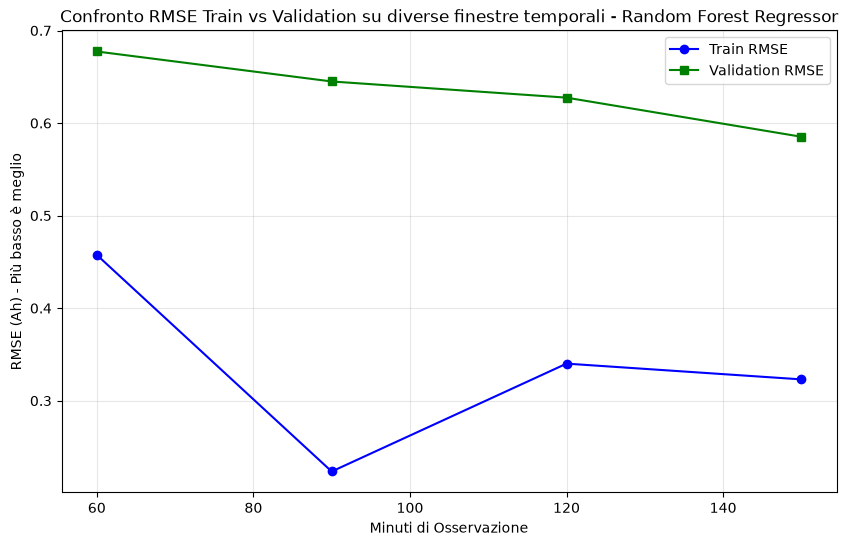

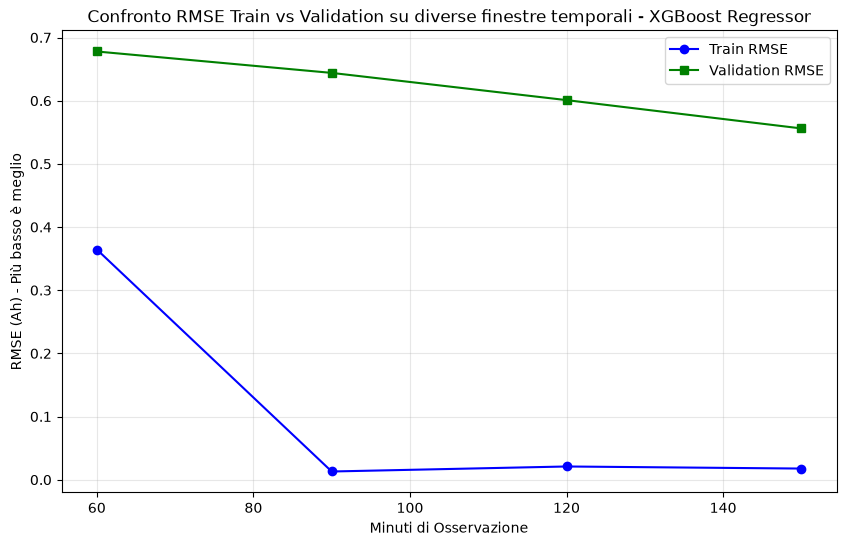

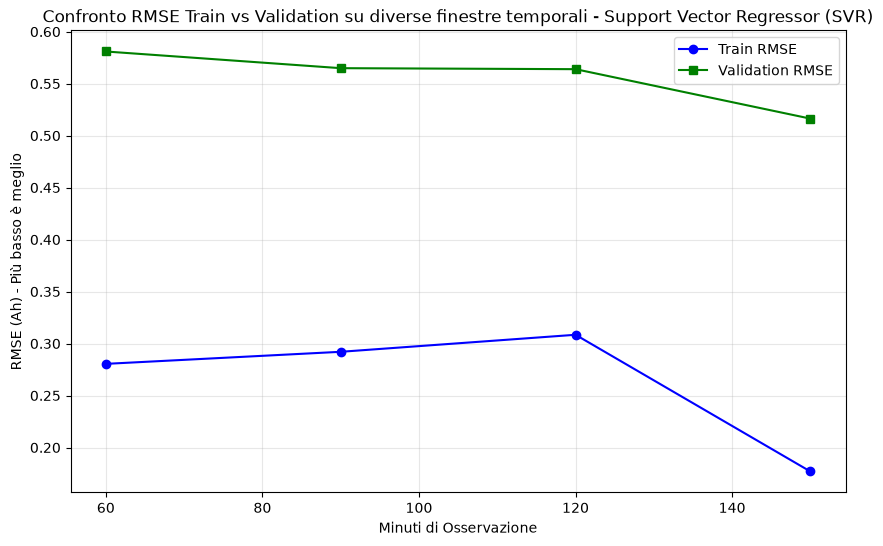

=== Random Forest Regressor ===
 -> Minimo teorico assoluto: 0.585 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.585 Ah)

=== XGBoost Regressor ===
 -> Minimo teorico assoluto: 0.556 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.556 Ah)

=== Support Vector Regressor (SVR) ===
 -> Minimo teorico assoluto: 0.516 Ah
 -> Finestra ottima scelta (con compromesso): 150 minuti (RMSE: 0.516 Ah)

Selected index for best model Random Forest Regressor: 3
Selected index for best model XGBoost Regressor: 3
Selected index for best model Support Vector Regressor (SVR): 3


In [21]:
ARR_MINUTI_OSSERVAZIONE = [60,90,120,150]

rmse_train_list = []
rmse_val_list = []
modelli_reg_ottimi_list = []
feature_reg_selezionate_list = []
for timespan in ARR_MINUTI_OSSERVAZIONE:
    print(f"\n=== Analisi per finestra di osservazione: {timespan} minuti ===")
    modelli_reg_ottimi_tmp, feature_reg_selezionate_tmp, rmse_train_list_tmp, rmse_val_list_tmp = tune_and_diagnose_regression(
        cut_off_minute=timespan,
        battery_dict=battery_dict,
        summary_train_df=summary_train_df,
        file_train_val=file_train_val
    )
    rmse_train_list.append(rmse_train_list_tmp)
    rmse_val_list.append(rmse_val_list_tmp)
    modelli_reg_ottimi_list.append(modelli_reg_ottimi_tmp)
    feature_reg_selezionate_list.append(feature_reg_selezionate_tmp)

# Compare the RMSE values across different observation windows
# this should be done for each model
for model_name in modelli_regressione.keys():
    train_rmse = [rmse_train[model_name] for rmse_train in rmse_train_list]
    val_rmse = [rmse_val[model_name] for rmse_val in rmse_val_list]
    plt.figure(figsize=(10, 6))
    plt.plot(ARR_MINUTI_OSSERVAZIONE, train_rmse, marker='o', label='Train RMSE', color='blue')
    plt.plot(ARR_MINUTI_OSSERVAZIONE, val_rmse, marker='s', label='Validation RMSE', color='green')
    plt.title(f"Confronto RMSE Train vs Validation su diverse finestre temporali - {model_name}")
    plt.xlabel("Minuti di Osservazione")
    plt.ylabel("RMSE (Ah) - Più basso è meglio")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.show()

# Choose one of the observation windows based on the RMSE comparison for final testing
# The window should be the one with the lowest validation RMSE and acceptable train RMSE (to avoid overfitting)
#best_index = {}
final_regression_model = {}
final_feature_names = {}
'''for model_name in modelli_regressione.keys():
    best_index[model_name] = np.argmin([rmse_val[model_name] for rmse_val in rmse_val_list])
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    print(f"Best observation window for {model_name}: {best_observation_window} minutes")'''

# Impostiamo una tolleranza: quanti Ah siamo disposti a sacrificare per avere la predizione prima?
TOLLERANZA_AH = 0.025 

best_index = {}
for model_name in modelli_regressione.keys():
    # Estrarre la lista degli RMSE di validazione per il modello corrente
    val_rmse_vettore = [rmse_val[model_name] for rmse_val in rmse_val_list]
    
    # Trova il minimo assoluto (la tua vecchia euristica)
    min_rmse_assoluto = np.min(val_rmse_vettore)
    
    # Trova tutti gli indici in cui l'errore è vicino al minimo entro la tolleranza
    indici_accettabili = np.where(val_rmse_vettore <= (min_rmse_assoluto + TOLLERANZA_AH))[0]
    
    # Tra gli indici accettabili, prendiamo il PRIMO (ovvero la finestra temporale più BREVE/PRECOCE)
    best_index[model_name] = indici_accettabili[0]
    
    best_observation_window = ARR_MINUTI_OSSERVAZIONE[best_index[model_name]]
    rmse_scelto = val_rmse_vettore[best_index[model_name]]
    
    print(f"=== {model_name} ===")
    print(f" -> Minimo teorico assoluto: {min_rmse_assoluto:.3f} Ah")
    print(f" -> Finestra ottima scelta (con compromesso): {best_observation_window} minuti (RMSE: {rmse_scelto:.3f} Ah)\n")

for model_name, index in best_index.items():
    print(f"Selected index for best model {model_name}: {index}")
    final_regression_model[model_name] = modelli_reg_ottimi_list[index][model_name]
    final_feature_names[model_name] = feature_reg_selezionate_list[index]

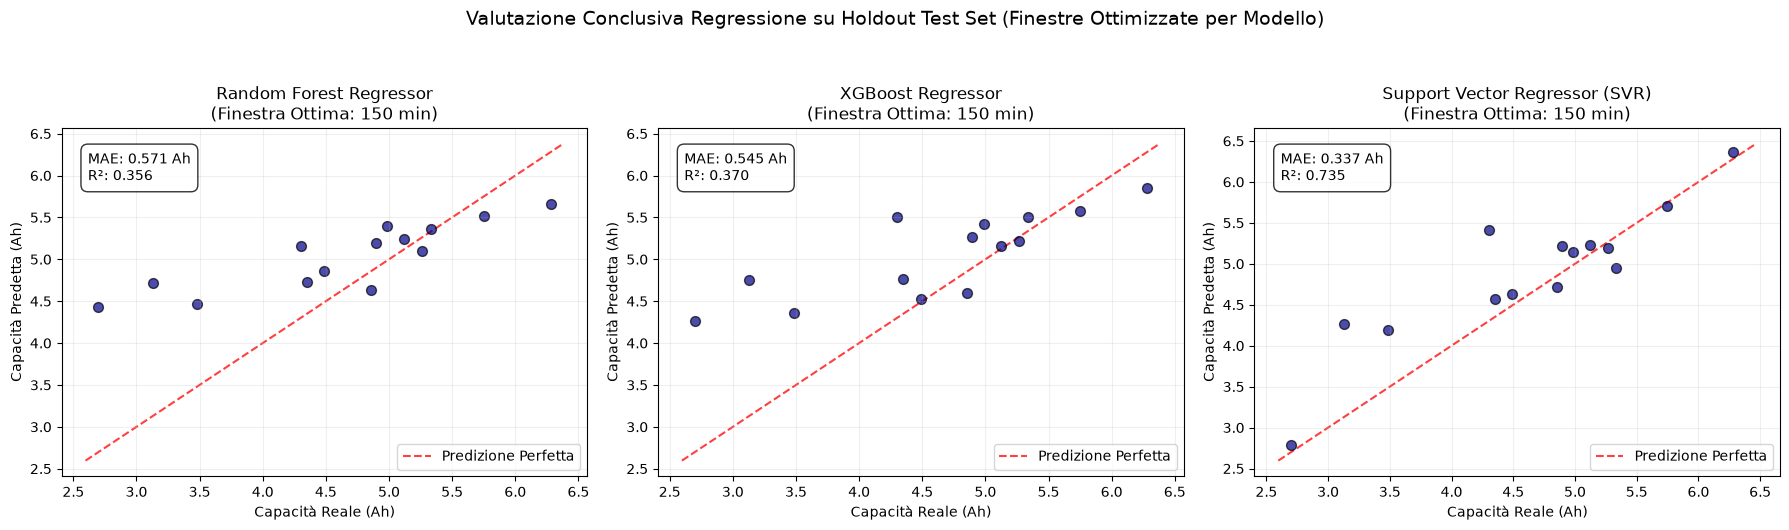

In [22]:
# 2. Predizione e Plotting True vs Predicted (Inizializziamo la figura prima del ciclo)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Cicliamo in modo robusto su ciascun modello autonomamente
for idx, (name, pipeline_ottima) in enumerate(final_regression_model.items()):
    
    # CORREZIONE 1: Recuperiamo la finestra specifica ottimale per QUESTO modello
    model_best_window = ARR_MINUTI_OSSERVAZIONE[best_index[name]]
    # CORREZIONE 2: Recuperiamo la lista esatta delle feature estratte per QUELLA finestra
    model_feature_names = final_feature_names[name]
    
    # 1. Costruzione della matrice di TEST (Holdout) mirata sulla specifica finestra del modello
    test_regression_records = []
    for file_name in file_holdout_test:
        df_bat = battery_dict[file_name]
        y_val = summary_test_df[summary_test_df['file_name'] == file_name]['final_capacity'].values[0]
        
        # Estraiamo le feature storiche usando il cut-off ottimale del modello corrente
        # Usiamo le variabili globali AMPIEZZA_BLOCCO_MINUTI e NUMERO_LAG se definite, altrimenti valori nativi (10 e 3)
        base_w = AMPIEZZA_BLOCCO_MINUTI if 'AMPIEZZA_BLOCCO_MINUTI' in globals() else 10
        n_steps = NUMERO_LAG if 'NUMERO_LAG' in globals() else 3
        
        feat_reg = extract_regression_lagged_features(
            df_bat, base_window_min=base_w, steps=n_steps, end_minute=model_best_window
        )
        
        if feat_reg is not None:
            feat_reg['file_name'] = file_name
            feat_reg['target_capacity'] = y_val
            test_regression_records.append(feat_reg)
            
    # Se per motivi di lunghezza dei CSV l'holdout fallisse l'estrazione su finestre lunghe (es. 300 min)
    if not test_regression_records:
        print(f"⚠️ Attenzione: Impossibile estrarre dati di test per {name} alla finestra {model_best_window} min.")
        continue
        
    df_reg_test = pd.DataFrame(test_regression_records).bfill().ffill()
    
    # CORREZIONE 3: Estraiamo la matrice usando le feature specifiche salvate nel dizionario
    X_test_r = df_reg_test[model_feature_names].values
    y_test_r = df_reg_test['target_capacity'].values
    
    # Il modello è già addestrato e configurato, facciamo il predict
    y_pred_r = pipeline_ottima.predict(X_test_r)
    
    # Calcolo delle metriche di test reali
    mae = mean_absolute_error(y_test_r, y_pred_r)
    r2 = r2_score(y_test_r, y_pred_r)
    
    # Grafica sul sotto-plot del modello corrente
    ax = axes[idx]
    ax.scatter(y_test_r, y_pred_r, color='darkblue', alpha=0.7, edgecolors='k', s=50)
    
    # Linea di riferimento a 45 gradi
    lims = [min(y_test_r.min(), y_pred_r.min()) - 0.1, max(y_test_r.max(), y_pred_r.max()) + 0.1]
    ax.plot(lims, lims, 'r--', alpha=0.75, zorder=0, label="Predizione Perfetta")
    
    # Titolo dinamico che specifica anche quanti minuti sono serviti a quel modello
    ax.set_title(f"{name}\n(Finestra Ottima: {model_best_window} min)")
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.grid(True, alpha=0.2)
    ax.text(0.05, 0.85, f"MAE: {mae:.3f} Ah\nR²: {r2:.3f}", 
            transform=ax.transAxes, bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle("Valutazione Conclusiva Regressione su Holdout Test Set (Finestre Ottimizzate per Modello)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# Deep Learning Models

In [23]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, Conv1D, GlobalAveragePooling1D, LeakyReLU, MaxPooling1D, Flatten
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import StratifiedShuffleSplit


In [24]:

# Costruisce summary_df dai CSV grezzi (valori non ricampionati) per il Deep Learning
records = []
for file in sorted(os.listdir(RAW_CSV_FOLDER)):
    if file.endswith(".csv"):
        df_raw = pd.read_csv(os.path.join(RAW_CSV_FOLDER, file), sep=';')
        final_capacity = float(df_raw['Capacity (Ah)'].iloc[-1])
        records.append({'file_name': file, 'final_capacity': final_capacity})

summary_df = pd.DataFrame(records)
# Manteniamo solo le batterie presenti in battery_dict (quelle effettivamente caricate)
summary_df = summary_df[summary_df['file_name'].isin(battery_dict.keys())].reset_index(drop=True)
print(f"✓ summary_df costruito: {len(summary_df)} batterie, final_capacity dtype: {summary_df['final_capacity'].dtype}")


✓ summary_df costruito: 66 batterie, final_capacity dtype: float64


In [25]:

# 1. Creiamo delle fasce (bin) basate sulla capacità finale
# summary_df è già costruito dalla cella precedente con i valori raw (non ricampionati)
bins = [0, 3.0, 4.0, 5.0, np.inf]
labels = [1, 2, 3, 4]  # 4 categorie: molto degradata, degrado medio, lieve, sana

summary_df['capacity_bin'] = pd.cut(summary_df['final_capacity'], bins=bins, labels=labels, include_lowest=True)

# Verifica che non ci siano NaN nei bin (batterie fuori range)
nan_bins = summary_df['capacity_bin'].isna().sum()
if nan_bins > 0:
    print(f"⚠️ Attenzione: {nan_bins} batterie fuori dai bin, verranno escluse dallo split stratificato.")
    summary_df = summary_df.dropna(subset=['capacity_bin']).reset_index(drop=True)

# 2. Configuriamo lo split stratificato per isolare l'Holdout Test Set (es. 20%)
split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

for train_index, test_index in split.split(summary_df, summary_df['capacity_bin']):
    strat_train_set = summary_df.iloc[train_index]
    strat_test_set = summary_df.iloc[test_index]

# Estraiamo le liste dei file per il Deep Learning
file_train_val = strat_train_set['file_name'].tolist()
file_holdout_test = strat_test_set['file_name'].tolist()

summary_train_df = summary_df[summary_df['file_name'].isin(file_train_val)][['file_name', 'final_capacity']].reset_index(drop=True)
summary_test_df = summary_df[summary_df['file_name'].isin(file_holdout_test)][['file_name', 'final_capacity']].reset_index(drop=True)

print(f"Batterie nel Train/Val set: {len(summary_train_df)}")
print(f"Batterie nel Test set: {len(summary_test_df)}")

# Verifica anti-leakage
overlap = set(file_train_val).intersection(set(file_holdout_test))
assert len(overlap) == 0, "ERRORE: Sovrapposizione tra train e test!"
print("✓ Nessuna sovrapposizione tra train e test (anti-leakage OK)")


Batterie nel Train/Val set: 52
Batterie nel Test set: 14
✓ Nessuna sovrapposizione tra train e test (anti-leakage OK)


In [ ]:
def build_sequential_tensor(file_list, battery_dict, summary_df, cut_off_minute=150, resolution_min=1):
    """
    Tensore 3D con 4 canali: V, C, dV/dt, dC/dt.
    - d²V/dt² rimossa (>70σ di outlier su dati ricampionati).
    - Derivate calcolate su segnale smoothed (rolling 5 min) prima della diff.
    - Clamp fisico su entrambe le derivate.
    dC/dt è il predittore fisicamente più diretto della capacità finale:
    una batteria degradata si scarica più in fretta dall'inizio del test.
    """
    X_list = []
    y_list = []
    files_in_tensor = []

    target_timesteps = np.arange(0, cut_off_minute + resolution_min, resolution_min)

    for file_name in file_list:
        df_bat = battery_dict[file_name]
        y_val = summary_df[summary_df['file_name'] == file_name]['final_capacity'].values[0]

        df_truncated = df_bat[df_bat['elapsed_min'] <= cut_off_minute].copy()
        if df_truncated['elapsed_min'].max() < (cut_off_minute - 1):
            continue

        df_truncated['Tensione (V)'] = df_truncated['Tensione (V)'].ffill().bfill()
        df_truncated['Capacity (Ah)'] = df_truncated['Capacity (Ah)'].ffill().bfill()
        df_truncated = df_truncated.sort_values('elapsed_min')

        v_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Tensione (V)'])
        c_interp = np.interp(target_timesteps, df_truncated['elapsed_min'], df_truncated['Capacity (Ah)'])

        if np.isnan(v_interp).any() or np.isnan(c_interp).any():
            v_interp = pd.Series(v_interp).ffill().bfill().values
            c_interp = pd.Series(c_interp).ffill().bfill().values

        # dV/dt — smoothing prima per ridurre picchi da transizioni di fase
        v_smooth = pd.Series(v_interp).rolling(window=5, center=True, min_periods=1).mean().values
        v_deriv = np.diff(v_smooth) / resolution_min
        v_deriv = np.insert(v_deriv, 0, 0.0)
        v_deriv = np.clip(v_deriv, -0.5, 0.5)   # ±0.5 V/min max fisicamente plausibile

        # dC/dt — la capacità varia lentamente; clip a ±0.05 Ah/min
        c_smooth = pd.Series(c_interp).rolling(window=5, center=True, min_periods=1).mean().values
        c_deriv = np.diff(c_smooth) / resolution_min
        c_deriv = np.insert(c_deriv, 0, 0.0)
        c_deriv = np.clip(c_deriv, -0.05, 0.05)  # batteria che scarica: valori negativi

        # 4 canali: V, C, dV/dt, dC/dt
        battery_matrix = np.column_stack((v_interp, c_interp, v_deriv, c_deriv))

        X_list.append(battery_matrix)
        y_list.append(y_val)
        files_in_tensor.append(file_name)

    return np.array(X_list), np.array(y_list), files_in_tensor


CUT_OFF_DL = 150
N_SPLITS = 8

X_train_raw, y_train_dl, files_train_dl = build_sequential_tensor(
    file_train_val, battery_dict, summary_train_df, cut_off_minute=CUT_OFF_DL)
X_test_raw, y_test_dl, files_test_dl = build_sequential_tensor(
    file_holdout_test, battery_dict, summary_test_df, cut_off_minute=CUT_OFF_DL)

N_BATTERIE_TR, N_TIMESTEPS, N_CANALI = X_train_raw.shape
N_BATTERIE_TE, _, _ = X_test_raw.shape

CLIP_SIGMA = 5
scaler_dl = StandardScaler()
X_train_flat = X_train_raw.reshape(-1, N_CANALI)
X_train_scaled_flat = np.clip(scaler_dl.fit_transform(X_train_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_train_dl = X_train_scaled_flat.reshape(N_BATTERIE_TR, N_TIMESTEPS, N_CANALI)

X_test_flat = X_test_raw.reshape(-1, N_CANALI)
X_test_scaled_flat = np.clip(scaler_dl.transform(X_test_flat), -CLIP_SIGMA, CLIP_SIGMA)
X_test_dl = X_test_scaled_flat.reshape(N_BATTERIE_TE, N_TIMESTEPS, N_CANALI)

print(f"✓ Tensori pronti — {N_CANALI} canali (V, C, dV/dt, dC/dt)")
print(f"-> Shape X_train_dl: {X_train_dl.shape}  |  X_test_dl: {X_test_dl.shape}")
print(f"-> Range dopo clip:  [{X_train_dl.min():.2f}, {X_train_dl.max():.2f}]")
print(f"-> NaN nel train:    {np.isnan(X_train_dl).any()}")


✓ Tensori pronti — 4 canali (V, C, dV/dt, dC/dt)
-> Shape X_train_dl: (52, 151, 4)  |  X_test_dl: (14, 151, 4)
-> Range dopo clip:  [-5.00, 5.00]
-> NaN nel train:    False


In [27]:
from tensorflow.keras.layers import MaxPooling1D, Flatten

def build_lstm_model(input_shape):
    model = Sequential([
        Input(shape=input_shape),
        LSTM(64, activation='tanh', recurrent_activation='sigmoid',
             recurrent_dropout=0.1, return_sequences=False),
        Dropout(0.2),
        Dense(16, kernel_regularizer=l2(0.005)),
        LeakyReLU(negative_slope=0.1),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.005, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


def build_cnn1d_model(input_shape):
    """
    Architettura con Flatten: preserva la struttura temporale locale che GlobalAveragePooling1D
    annullerebbe. Con dataset piccoli (50 campioni) la memorizzazione spaziale
    + L2/Dropout è più efficace del pooling globale.
    """
    model = Sequential([
        Input(shape=input_shape),
        Conv1D(filters=32, kernel_size=7, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),           # 151 → 75
        Conv1D(filters=64, kernel_size=5, activation='relu', padding='same'),
        MaxPooling1D(pool_size=2),           # 75 → 37
        Flatten(),                           # 37 × 64 = 2368 feature
        Dense(32, kernel_regularizer=l2(0.005), activation='relu'),
        Dropout(0.3),
        Dense(1, activation='linear')
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.003, clipnorm=1.0),
                  loss='mse', metrics=['mae'])
    return model


In [28]:

# === DIAGNOSI: analisi per canale dei dati scalati ===
canali = ['Tensione (V)', 'Capacity (Ah)', 'dV/dt', 'dC/dt']
print("Statistiche per canale DOPO StandardScaler + clip:\n")
print(f"{'Canale':<20} {'Min':>10} {'Max':>10} {'Std':>10} {'|>5σ| (%)':>12}")
print("-"*65)
for i, nome in enumerate(canali):
    ch = X_train_dl[:, :, i].flatten()
    pct_outlier = np.mean(np.abs(ch) > 5) * 100
    print(f"{nome:<20} {ch.min():>10.2f} {ch.max():>10.2f} {ch.std():>10.4f} {pct_outlier:>11.2f}%")

print(f"\nStd target (y_train_dl): {y_train_dl.std():.4f} Ah")
print(f"Mean target:             {y_train_dl.mean():.4f} Ah")
print(f"→ RMSE lazy predictor:   {y_train_dl.std():.4f} Ah")


Statistiche per canale DOPO StandardScaler + clip:

Canale                      Min        Max        Std    |>5σ| (%)
-----------------------------------------------------------------
Tensione (V)              -5.00       5.00     0.9607        0.00%
Capacity (Ah)             -0.88       5.00     0.8360        0.00%
dV/dt                     -5.00       5.00     0.2512        0.00%
dC/dt                     -5.00       3.61     0.6334        0.00%

Std target (y_train_dl): 0.8097 Ah
Mean target:             4.9151 Ah
→ RMSE lazy predictor:   0.8097 Ah


In [29]:
# Strutture dati per raccogliere la storia dell'addestramento per i grafici
training_histories = {"LSTM": [], "CNN-1D": []}
test_predictions = {"LSTM": None, "CNN-1D": None}
metriche_finali = {}

gkf = GroupKFold(n_splits=N_SPLITS)
funzioni_modelli = {"LSTM": build_lstm_model, "CNN-1D": build_cnn1d_model}

for name, build_func in funzioni_modelli.items():
    print("\n" + "="*70)
    print(f" AVVIO TRAINING E TRACCIAMENTO STORIA PER: {name}")
    print("="*70)
    
    oof_predictions = np.zeros(len(y_train_dl))
    trained_fold_models = []
    
    for fold, (train_idx, val_idx) in enumerate(gkf.split(X_train_dl, y_train_dl, groups=files_train_dl)):
        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx], y_train_dl[val_idx]
        
        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))
        
        # Pazienza impostata a 30 epoche per dare modo di vedere la curva stabilizzarsi
        early_stop = EarlyStopping(monitor='val_loss', patience=30, restore_best_weights=True)

        lr_reducer = ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,        # Moltiplica il LR per 0.5 (lo dimezza)
            patience=10,       # Attende 10 epoche senza miglioramenti
            min_lr=0.0001,     # Non scendere sotto questa soglia
            verbose=0
        )
        
        history = model.fit(
            X_tr_f, y_tr_f,
            validation_data=(X_val_f, y_val_f),
            epochs=200,
            batch_size=len(X_tr_f),
            callbacks=[early_stop, lr_reducer],
            verbose=0
        )
        
        # Salviamo la storia del fold corrente nel nostro dizionario
        training_histories[name].append(history.history)
        
        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold + 1} completato. Epoche: {len(history.history['loss'])} | Val RMSE: {fold_rmse:.4f} Ah")
        
        trained_fold_models.append(model)
        
    # Calcolo predizioni sul Test Set (Holdout)
    temp_test_preds = []
    for model_fold in trained_fold_models:
        preds = model_fold.predict(X_test_dl, verbose=0).flatten()
        temp_test_preds.append(preds)
        
    final_test_preds = np.mean(temp_test_preds, axis=0)
    test_predictions[name] = final_test_preds
    
    mse = mean_squared_error(y_test_dl, final_test_preds)
    metriche_finali[name] = {"MSE": mse, "RMSE": np.sqrt(mse), "MAE": mean_absolute_error(y_test_dl, final_test_preds), "R2": r2_score(y_test_dl, final_test_preds)}

# --- STAMPA TABELLARE DELLE METRICHE COMPARATIVE ---
df_metriche = pd.DataFrame(metriche_finali).T
print("\n" + "="*70)
print(" TABELLA COMPARATIVA DELLE PERFORMANCE SUL TEST SET GENERALE")
print("="*70)
print(df_metriche.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format, 
    'MAE': '{:,.4f}'.format, 'R2': '{:,.4f}'.format
}))
print("="*70)


 AVVIO TRAINING E TRACCIAMENTO STORIA PER: LSTM
 -> Fold 1 completato. Epoche: 69 | Val RMSE: 0.4980 Ah
 -> Fold 2 completato. Epoche: 59 | Val RMSE: 0.6871 Ah
 -> Fold 3 completato. Epoche: 45 | Val RMSE: 1.1336 Ah
 -> Fold 4 completato. Epoche: 36 | Val RMSE: 0.5479 Ah
 -> Fold 5 completato. Epoche: 35 | Val RMSE: 0.7014 Ah

 AVVIO TRAINING E TRACCIAMENTO STORIA PER: CNN-1D
 -> Fold 1 completato. Epoche: 108 | Val RMSE: 0.8957 Ah
 -> Fold 2 completato. Epoche: 51 | Val RMSE: 0.9005 Ah
 -> Fold 3 completato. Epoche: 86 | Val RMSE: 0.7153 Ah
 -> Fold 4 completato. Epoche: 200 | Val RMSE: 0.2670 Ah
 -> Fold 5 completato. Epoche: 77 | Val RMSE: 0.8055 Ah

 TABELLA COMPARATIVA DELLE PERFORMANCE SUL TEST SET GENERALE
          MSE   RMSE    MAE     R2
LSTM   0.4560 0.6753 0.5712 0.0105
CNN-1D 0.3575 0.5979 0.4367 0.2241


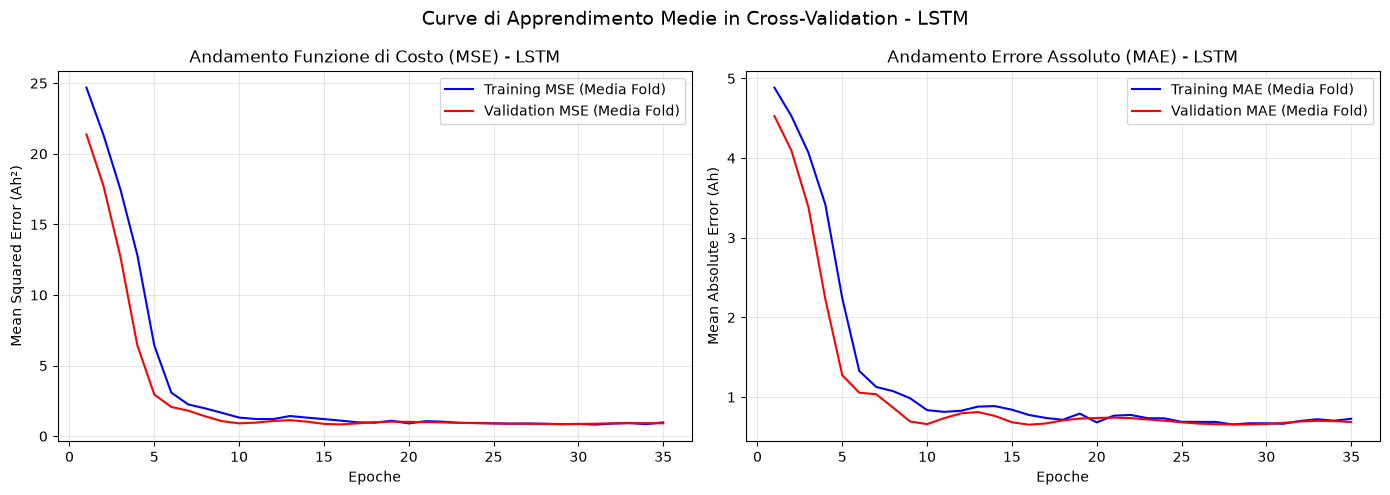

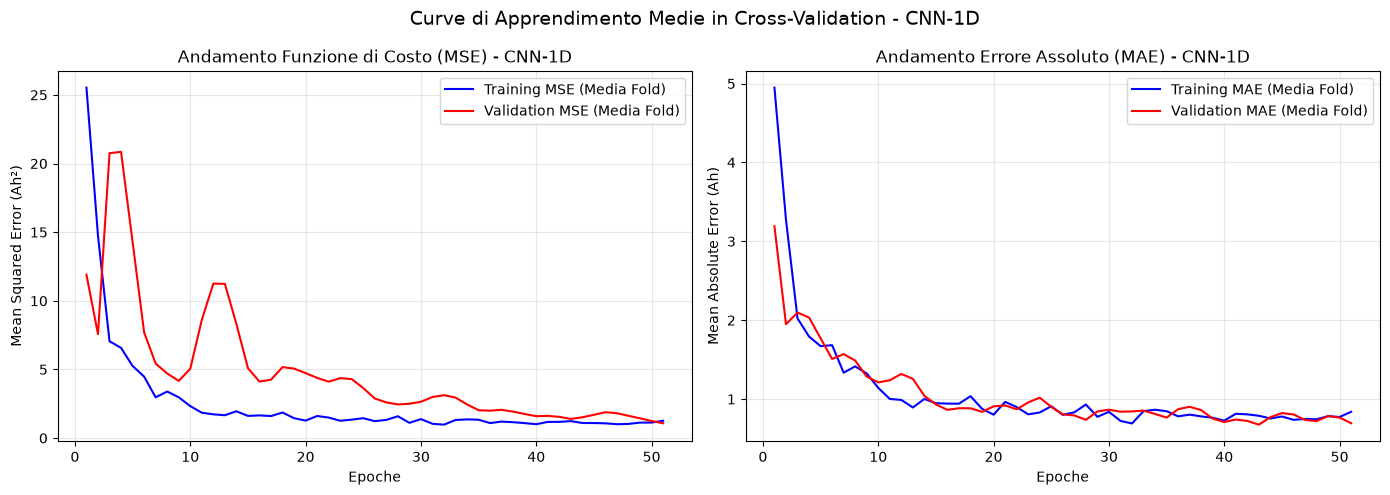

In [30]:
# Creazione dei grafici delle curve di errore
for name in ["LSTM", "CNN-1D"]:
    histories = training_histories[name]
    
    # Poiché l'EarlyStopping interrompe i fold a epoche diverse, troviamo la lunghezza minima
    min_epochs = min([len(h['loss']) for h in histories])
    
    # Allineiamo le loss tagliando alla lunghezza minima per poter fare la media matematica
    train_loss_folds = np.array([h['loss'][:min_epochs] for h in histories])
    val_loss_folds = np.array([h['val_loss'][:min_epochs] for h in histories])
    train_mae_folds = np.array([h['mae'][:min_epochs] for h in histories])
    val_mae_folds = np.array([h['val_mae'][:min_epochs] for h in histories])
    
    # Calcoliamo la media lungo i 5 fold
    mean_train_loss = np.mean(train_loss_folds, axis=0)
    mean_val_loss = np.mean(val_loss_folds, axis=0)
    mean_train_mae = np.mean(train_mae_folds, axis=0)
    mean_val_mae = np.mean(val_mae_folds, axis=0)
    
    epochs_range = range(1, min_epochs + 1)
    
    # Generazione della figura con due sotto-grafici (Loss a sinistra, MAE a destra)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    # Subplot 1: MSE (Funzione di Loss)
    ax1.plot(epochs_range, mean_train_loss, 'b-', label='Training MSE (Media Fold)')
    ax1.plot(epochs_range, mean_val_loss, 'r-', label='Validation MSE (Media Fold)')
    ax1.set_title(f'Andamento Funzione di Costo (MSE) - {name}')
    ax1.set_xlabel('Epoche')
    ax1.set_ylabel('Mean Squared Error (Ah²)')
    ax1.grid(True, alpha=0.3)
    ax1.legend()
    
    # Subplot 2: MAE
    ax2.plot(epochs_range, mean_train_mae, 'b-', label='Training MAE (Media Fold)')
    ax2.plot(epochs_range, mean_val_mae, 'r-', label='Validation MAE (Media Fold)')
    ax2.set_title(f'Andamento Errore Assoluto (MAE) - {name}')
    ax2.set_xlabel('Epoche')
    ax2.set_ylabel('Mean Absolute Error (Ah)')
    ax2.grid(True, alpha=0.3)
    ax2.legend()
    
    plt.suptitle(f"Curve di Apprendimento Medie in Cross-Validation - {name}", fontsize=14)
    plt.tight_layout()
    plt.show()

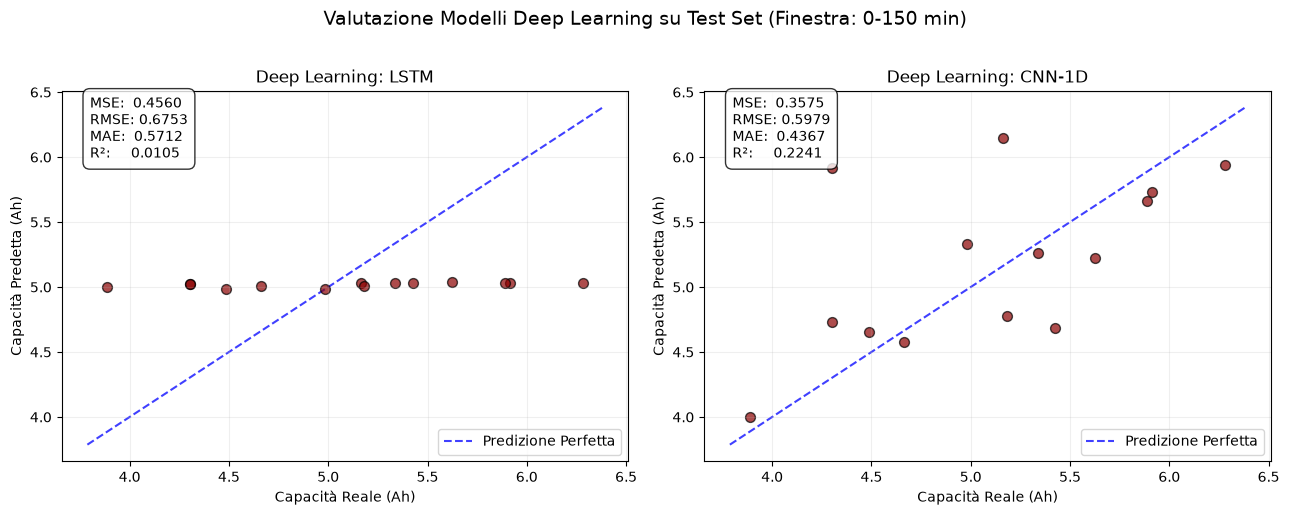

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for idx, name in enumerate(["LSTM", "CNN-1D"]):
    y_pred_dl = test_predictions[name]
    metrics = metriche_finali[name]
    
    ax = axes[idx]
    ax.scatter(y_test_dl, y_pred_dl, color='darkred', alpha=0.7, edgecolors='k', s=50)
    
    # Diagonale perfetta
    lims = [min(y_test_dl.min(), y_pred_dl.min()) - 0.1, max(y_test_dl.max(), y_pred_dl.max()) + 0.1]
    ax.plot(lims, lims, 'b--', alpha=0.75, zorder=0, label="Predizione Perfetta")
    
    ax.set_title(f"Deep Learning: {name}")
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.grid(True, alpha=0.2)
    
    # Box testuale con tutte le metriche richieste dal docente
    info_text = f"MSE:  {metrics['MSE']:.4f}\nRMSE: {metrics['RMSE']:.4f}\nMAE:  {metrics['MAE']:.4f}\nR²:     {metrics['R2']:.4f}"
    ax.text(0.05, 0.82, info_text, transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
    ax.legend(loc='lower right')

plt.suptitle(f"Valutazione Modelli Deep Learning su Test Set (Finestra: 0-{CUT_OFF_DL} min)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## Data Augmentation — Gaussian Noise Injection

La data augmentation con rumore gaussiano è sicura perché:
- `battery_dict` (dati raw) non viene mai modificato
- Il rumore viene aggiunto **solo alle copie del training fold** all'interno di ogni iterazione CV
- Validation e test set ricevono dati originali puliti
- Il target `y` (capacità finale reale) è **invariato** per ogni copia aumentata
- Il rumore è **zero-mean** → nessuno shift sistematico del segnale

Livelli di rumore scelti in spazio scalato (std≈1):
| Canale | σ rumore (scalato) | ≈ Valore fisico |
|---|---|---|
| Tensione (V) | 0.03 | ~15-30 mV (precisione BMS tipica: ±10 mV) |
| Capacità (Ah) | 0.03 | ~5-20 mAh (errore integrazione corrente) |
| dV/dt | 0.01 | perturbazione sul segnale già smoothed |
| dC/dt | 0.01 | perturbazione sul segnale già smoothed |


In [32]:

# Livelli di rumore per canale nello spazio scalato (std≈1)
# Proporzionali alla precisione reale dei sensori BMS per batterie Li-ion
AUG_NOISE_SIGMAS = [0.03, 0.03, 0.01, 0.01]  # [V, C, dV/dt, dC/dt]
AUG_N_COPIES = 3                               # dataset 4× più grande

def augment_training_fold(X_tr, y_tr, n_copies=3, noise_sigmas=None, seed=None):
    """
    Aumenta il training fold aggiungendo n_copies copie con rumore gaussiano.

    Garanzie di correttezza:
    - Chiamata SOLO su X_tr (fold di train); X_val e X_test non vengono mai toccati.
    - y rimane identico per ogni copia aumentata: il target fisico (capacità finale)
      non cambia per una batteria, indipendentemente dal rumore di misura.
    - Il rumore è zero-mean: nessuno shift sistematico del segnale.
    - Il clip a ±CLIP_SIGMA preserva i limiti già imposti dallo scaling.
    """
    if noise_sigmas is None:
        noise_sigmas = AUG_NOISE_SIGMAS

    rng = np.random.default_rng(seed)
    n_samples, n_timesteps, n_channels = X_tr.shape

    X_list = [X_tr]
    y_list = [y_tr]

    for copy_idx in range(n_copies):
        noise = np.zeros_like(X_tr)
        for ch, sigma in enumerate(noise_sigmas[:n_channels]):
            noise[:, :, ch] = rng.normal(0.0, sigma, (n_samples, n_timesteps))
        # Clip per mantenere i dati entro i limiti dello spazio scalato
        X_noisy = np.clip(X_tr + noise, -CLIP_SIGMA, CLIP_SIGMA)
        X_list.append(X_noisy)
        y_list.append(y_tr.copy())

    return np.concatenate(X_list, axis=0), np.concatenate(y_list, axis=0)


# Verifica rapida: il rumore non distorce la media dei segnali
rng_test = np.random.default_rng(0)
X_aug_check, y_aug_check = augment_training_fold(X_train_dl, y_train_dl,
                                                  n_copies=1, seed=0)
print("Verifica augmentation:")
print(f"  Campioni originali: {len(X_train_dl)} → dopo augmentation (×{AUG_N_COPIES+1}): "
      f"{len(X_train_dl) * (AUG_N_COPIES + 1)}")
print(f"  Media canale V originale: {X_train_dl[:,:,0].mean():.4f}  "
      f"| aumentato (1 copia): {X_aug_check[:,:,0].mean():.4f}  ← deve essere ≈ uguale")
print(f"  Target y invariato: {np.allclose(y_train_dl, y_aug_check[:len(y_train_dl)])}")


Verifica augmentation:
  Campioni originali: 52 → dopo augmentation (×4): 208
  Media canale V originale: -0.0013  | aumentato (1 copia): -0.0014  ← deve essere ≈ uguale
  Target y invariato: True


In [33]:

# ======================================================================
# TRAINING CON DATA AUGMENTATION
# Identico al training senza augmentation, con una sola differenza:
# all'interno di ogni fold, X_tr_f viene aumentato a 4× prima del fit.
# X_val_f e X_test_dl rimangono i dati originali puliti.
# ======================================================================
training_histories_aug = {"LSTM": [], "CNN-1D": []}
test_predictions_aug   = {"LSTM": None, "CNN-1D": None}
metriche_aug           = {}

gkf_aug = GroupKFold(n_splits=N_SPLITS)

for name, build_func in funzioni_modelli.items():
    print("\n" + "="*70)
    print(f" [AUG] TRAINING CON AUGMENTATION — {name}")
    print("="*70)

    oof_predictions_aug = np.zeros(len(y_train_dl))
    trained_fold_models_aug = []

    for fold, (train_idx, val_idx) in enumerate(
            gkf_aug.split(X_train_dl, y_train_dl, groups=files_train_dl)):

        X_tr_f, y_tr_f = X_train_dl[train_idx], y_train_dl[train_idx]
        X_val_f, y_val_f = X_train_dl[val_idx],  y_train_dl[val_idx]

        # ──── DATA AUGMENTATION (solo sul fold di training) ────────────
        X_tr_aug, y_tr_aug = augment_training_fold(
            X_tr_f, y_tr_f,
            n_copies=AUG_N_COPIES,
            noise_sigmas=AUG_NOISE_SIGMAS,
            seed=RANDOM_SEED + fold        # seed deterministico per riproducibilità
        )
        # ───────────────────────────────────────────────────────────────

        model = build_func(input_shape=(X_train_dl.shape[1], X_train_dl.shape[2]))

        early_stop_aug = EarlyStopping(monitor='val_loss', patience=30,
                                       restore_best_weights=True)
        lr_reducer_aug = ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                           patience=10, min_lr=0.0001, verbose=0)

        history = model.fit(
            X_tr_aug, y_tr_aug,
            validation_data=(X_val_f, y_val_f),   # ← validation ORIGINALE, non aumentata
            epochs=200,
            batch_size=16,                         # mini-batch: meglio con dataset aumentato
            callbacks=[early_stop_aug, lr_reducer_aug],
            verbose=0
        )

        training_histories_aug[name].append(history.history)

        val_preds = model.predict(X_val_f, verbose=0).flatten()
        oof_predictions_aug[val_idx] = val_preds
        fold_rmse = np.sqrt(mean_squared_error(y_val_f, val_preds))
        print(f" -> Fold {fold+1} | Epoche: {len(history.history['loss']):3d} "
              f"| Train size: {len(X_tr_aug)} ({len(X_tr_f)}×{AUG_N_COPIES+1}) "
              f"| Val RMSE: {fold_rmse:.4f} Ah")

        trained_fold_models_aug.append(model)

    # Predizioni medie sull'holdout (ensemble dei fold)
    temp_preds = [m.predict(X_test_dl, verbose=0).flatten()
                  for m in trained_fold_models_aug]
    final_preds_aug = np.mean(temp_preds, axis=0)
    test_predictions_aug[name] = final_preds_aug

    mse = mean_squared_error(y_test_dl, final_preds_aug)
    metriche_aug[name] = {
        "MSE":  mse,
        "RMSE": np.sqrt(mse),
        "MAE":  mean_absolute_error(y_test_dl, final_preds_aug),
        "R2":   r2_score(y_test_dl, final_preds_aug)
    }

df_metriche_aug = pd.DataFrame(metriche_aug).T
print("\n" + "="*70)
print(" [AUG] PERFORMANCE SUL TEST SET")
print("="*70)
print(df_metriche_aug.to_string(formatters={
    'MSE': '{:,.4f}'.format, 'RMSE': '{:,.4f}'.format,
    'MAE': '{:,.4f}'.format, 'R2':   '{:,.4f}'.format
}))
print("="*70)



 [AUG] TRAINING CON AUGMENTATION — LSTM
 -> Fold 1 | Epoche:  54 | Train size: 164 (41×4) | Val RMSE: 0.4029 Ah
 -> Fold 2 | Epoche:  43 | Train size: 164 (41×4) | Val RMSE: 0.6877 Ah
 -> Fold 3 | Epoche:  59 | Train size: 168 (42×4) | Val RMSE: 1.0251 Ah
 -> Fold 4 | Epoche: 106 | Train size: 168 (42×4) | Val RMSE: 0.4762 Ah
 -> Fold 5 | Epoche:  41 | Train size: 168 (42×4) | Val RMSE: 0.6316 Ah

 [AUG] TRAINING CON AUGMENTATION — CNN-1D
 -> Fold 1 | Epoche:  88 | Train size: 164 (41×4) | Val RMSE: 0.4062 Ah
 -> Fold 2 | Epoche:  84 | Train size: 164 (41×4) | Val RMSE: 0.8771 Ah
 -> Fold 3 | Epoche:  61 | Train size: 168 (42×4) | Val RMSE: 0.4494 Ah
 -> Fold 4 | Epoche: 142 | Train size: 168 (42×4) | Val RMSE: 0.3088 Ah
 -> Fold 5 | Epoche:  51 | Train size: 168 (42×4) | Val RMSE: 0.8251 Ah

 [AUG] PERFORMANCE SUL TEST SET
          MSE   RMSE    MAE      R2
LSTM   0.3778 0.6147 0.5222  0.1801
CNN-1D 0.5494 0.7412 0.4468 -0.1922


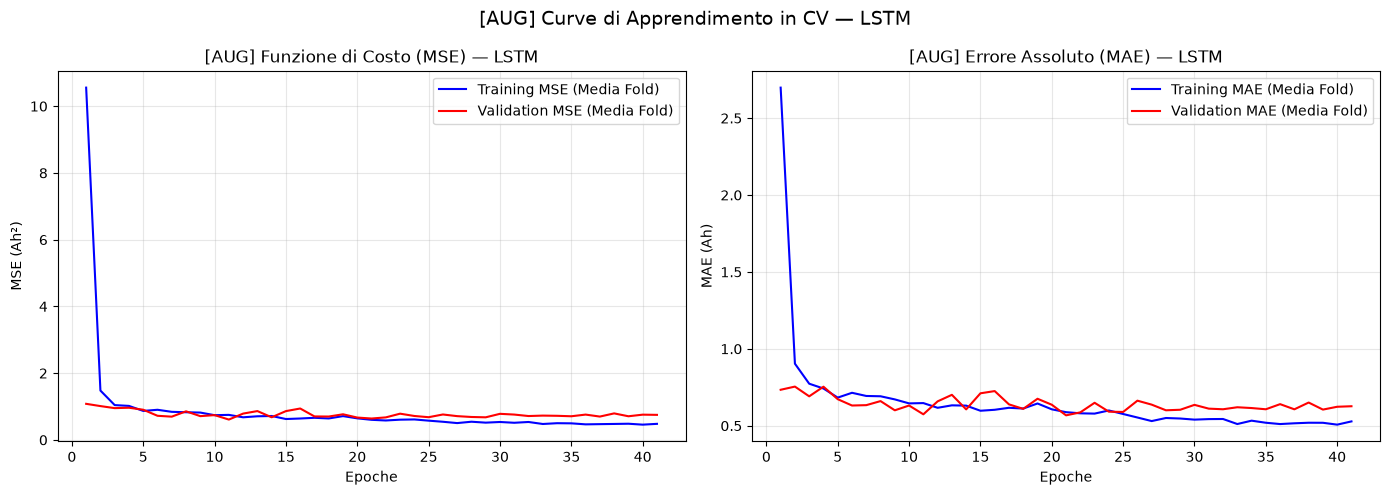

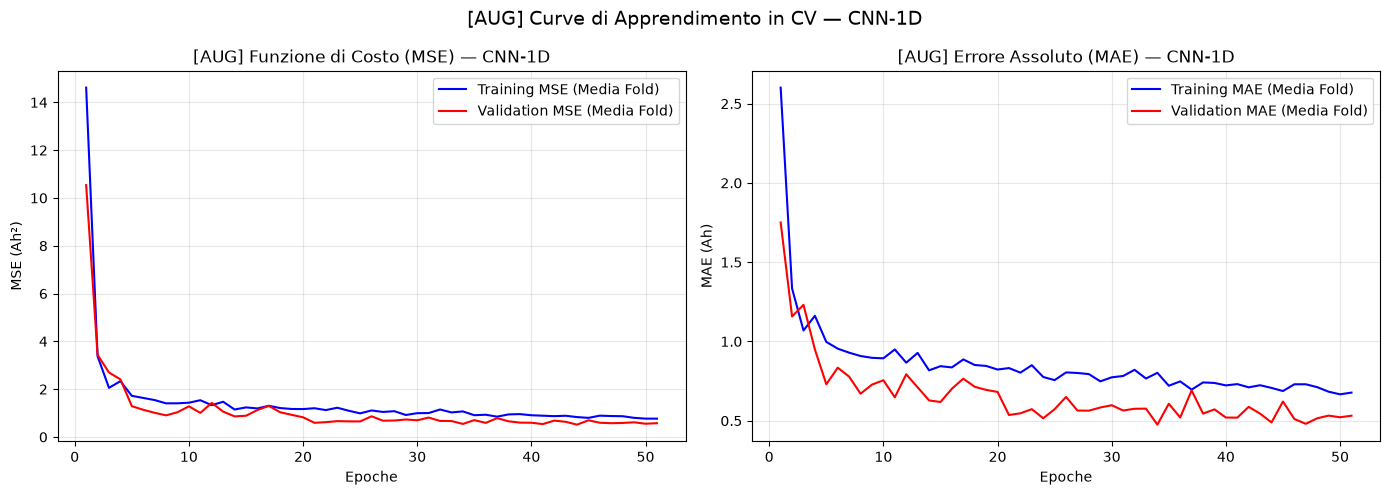

In [34]:

# Curve di apprendimento — Training con Augmentation
for name in ["LSTM", "CNN-1D"]:
    histories = training_histories_aug[name]
    min_epochs = min(len(h['loss']) for h in histories)

    train_loss  = np.mean([h['loss'][:min_epochs]    for h in histories], axis=0)
    val_loss    = np.mean([h['val_loss'][:min_epochs] for h in histories], axis=0)
    train_mae   = np.mean([h['mae'][:min_epochs]     for h in histories], axis=0)
    val_mae     = np.mean([h['val_mae'][:min_epochs]  for h in histories], axis=0)
    epochs_range = range(1, min_epochs + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(epochs_range, train_loss, 'b-', label='Training MSE (Media Fold)')
    ax1.plot(epochs_range, val_loss,   'r-', label='Validation MSE (Media Fold)')
    ax1.set_title(f'[AUG] Funzione di Costo (MSE) — {name}')
    ax1.set_xlabel('Epoche'); ax1.set_ylabel('MSE (Ah²)')
    ax1.grid(True, alpha=0.3); ax1.legend()

    ax2.plot(epochs_range, train_mae, 'b-', label='Training MAE (Media Fold)')
    ax2.plot(epochs_range, val_mae,   'r-', label='Validation MAE (Media Fold)')
    ax2.set_title(f'[AUG] Errore Assoluto (MAE) — {name}')
    ax2.set_xlabel('Epoche'); ax2.set_ylabel('MAE (Ah)')
    ax2.grid(True, alpha=0.3); ax2.legend()

    plt.suptitle(f"[AUG] Curve di Apprendimento in CV — {name}", fontsize=14)
    plt.tight_layout()
    plt.show()


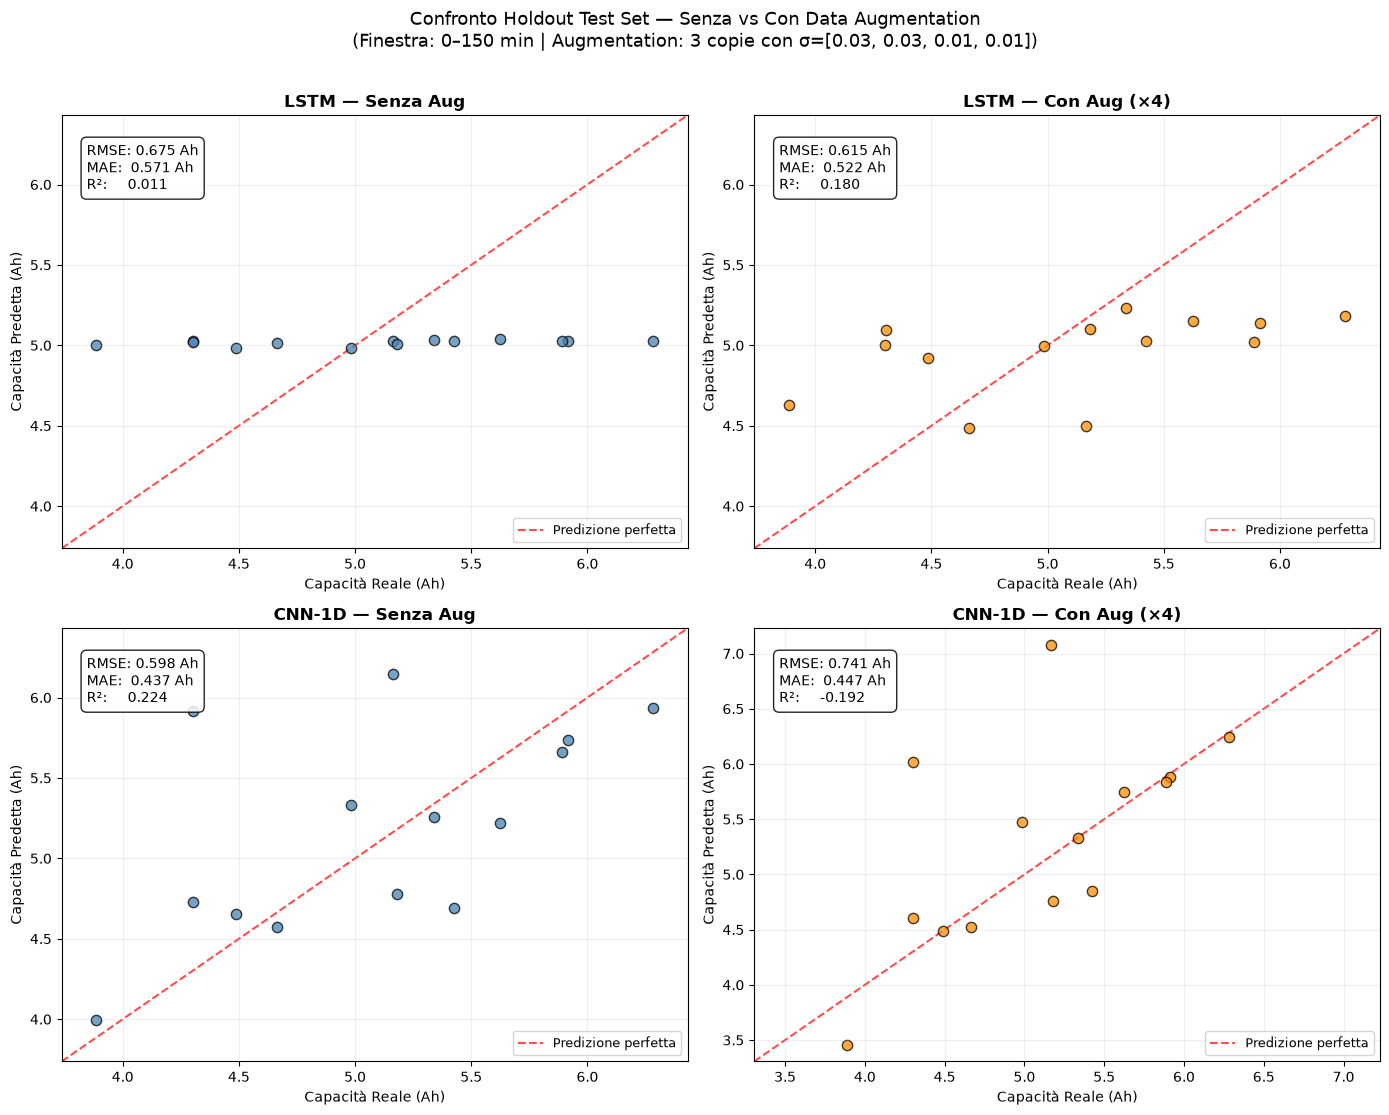


 TABELLA COMPARATIVA — No Augmentation vs Data Augmentation
Modello Training  RMSE (Ah)  MAE (Ah)      R²
   LSTM   No Aug     0.6753    0.5712  0.0105
   LSTM   Aug ×4     0.6147    0.5222  0.1801
 CNN-1D   No Aug     0.5979    0.4367  0.2241
 CNN-1D   Aug ×4     0.7412    0.4468 -0.1922

Delta RMSE (positivo = miglioramento con aug):
  LSTM:   +0.0606 Ah  |  ΔR²: +0.1696
  CNN-1D: -0.1433 Ah  |  ΔR²: -0.4164


In [35]:

# ======================================================================
# CONFRONTO FINALE: Senza Augmentation vs Con Augmentation
# 2 righe × 2 colonne:
#   riga 1 = LSTM  (no aug | aug)
#   riga 2 = CNN-1D (no aug | aug)
# ======================================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
configs = [
    ("LSTM",   test_predictions,     metriche_finali, "Senza Aug"),
    ("LSTM",   test_predictions_aug, metriche_aug,    f"Con Aug (×{AUG_N_COPIES+1})"),
    ("CNN-1D", test_predictions,     metriche_finali, "Senza Aug"),
    ("CNN-1D", test_predictions_aug, metriche_aug,    f"Con Aug (×{AUG_N_COPIES+1})"),
]

for (name, preds_dict, metrics_dict, label), ax in zip(configs, axes.flatten()):
    y_pred = preds_dict[name]
    m      = metrics_dict[name]

    ax.scatter(y_test_dl, y_pred, alpha=0.75, edgecolors='k', s=55,
               color='steelblue' if 'Senza' in label else 'darkorange')

    lims = [min(y_test_dl.min(), y_pred.min()) - 0.15,
            max(y_test_dl.max(), y_pred.max()) + 0.15]
    ax.plot(lims, lims, 'r--', alpha=0.7, zorder=0, label='Predizione perfetta')

    ax.set_title(f"{name} — {label}", fontsize=12, fontweight='bold')
    ax.set_xlabel("Capacità Reale (Ah)")
    ax.set_ylabel("Capacità Predetta (Ah)")
    ax.set_xlim(lims); ax.set_ylim(lims)
    ax.grid(True, alpha=0.2)
    ax.text(0.04, 0.83,
            f"RMSE: {m['RMSE']:.3f} Ah\nMAE:  {m['MAE']:.3f} Ah\nR²:     {m['R2']:.3f}",
            transform=ax.transAxes, fontsize=10,
            bbox=dict(facecolor='white', alpha=0.85, boxstyle='round,pad=0.4'))
    ax.legend(loc='lower right', fontsize=9)

plt.suptitle(
    f"Confronto Holdout Test Set — Senza vs Con Data Augmentation\n"
    f"(Finestra: 0–{CUT_OFF_DL} min | Augmentation: {AUG_N_COPIES} copie con σ={AUG_NOISE_SIGMAS})",
    fontsize=13, y=1.01
)
plt.tight_layout()
plt.show()

# ------ Tabella riassuntiva ------
rows = []
for name in ["LSTM", "CNN-1D"]:
    for label, md in [("No Aug", metriche_finali), (f"Aug ×{AUG_N_COPIES+1}", metriche_aug)]:
        m = md[name]
        rows.append({"Modello": name, "Training": label,
                     "RMSE (Ah)": round(m['RMSE'], 4),
                     "MAE (Ah)":  round(m['MAE'],  4),
                     "R²":        round(m['R2'],   4)})

df_confronto = pd.DataFrame(rows)
print("\n" + "="*65)
print(" TABELLA COMPARATIVA — No Augmentation vs Data Augmentation")
print("="*65)
print(df_confronto.to_string(index=False))
print("="*65)
delta_rmse_lstm  = metriche_finali["LSTM"]["RMSE"]   - metriche_aug["LSTM"]["RMSE"]
delta_rmse_cnn   = metriche_finali["CNN-1D"]["RMSE"] - metriche_aug["CNN-1D"]["RMSE"]
delta_r2_lstm    = metriche_aug["LSTM"]["R2"]        - metriche_finali["LSTM"]["R2"]
delta_r2_cnn     = metriche_aug["CNN-1D"]["R2"]      - metriche_finali["CNN-1D"]["R2"]
print(f"\nDelta RMSE (positivo = miglioramento con aug):")
print(f"  LSTM:   {delta_rmse_lstm:+.4f} Ah  |  ΔR²: {delta_r2_lstm:+.4f}")
print(f"  CNN-1D: {delta_rmse_cnn:+.4f} Ah  |  ΔR²: {delta_r2_cnn:+.4f}")
